In [31]:
import os
import scanpy
import scanpy as sc
import numpy as np
import pandas as pd

import random

random.seed(10)

In [32]:
# Directory h5ad data (Just test for a specific sample)
#os.chdir("/data/ciperi/Atlas_SSC/LUNG/GSE212109")
#directory_h5ad = "GSE212109.h5ad"
#adata_merged = scanpy.read_h5ad(directory_h5ad)

#print(adata_merged)

In [33]:
#print(adata_merged.raw.X)

In [34]:
import scanpy as sc
from pathlib import Path

# Base directory containing all GSE folders / h5ad files
base_dir = Path("/home/ciperi/data/Atlas_SSC/LUNG")

# Find all .h5ad files inside directories starting with GSE
h5ad_files = sorted(base_dir.glob("GSE*/**/*.h5ad"))
print(h5ad_files)

print(f"Found {len(h5ad_files)} .h5ad files:")
for f in h5ad_files:
    print("  -", f)

# Read each dataset
adatas = []
for f in h5ad_files:
    print(f"\nReading {f.name} ...")
    adata = sc.read_h5ad(f)

    # Add a metadata column with the dataset name
    adata.obs["dataset"] = f.parent.name

    # Optionally make variable names unique
    adata.var_names_make_unique()

    adatas.append(adata)

# 🧬 --- Gene overlap comparison before merging ---
gene_lists = [set(a.var_names) for a in adatas]
shared_genes = set.intersection(*gene_lists)
all_genes = set.union(*gene_lists)

print("\n🧬 Gene overlap summary:")
print(f" - Total unique genes across all datasets: {len(all_genes):,}")
print(f" - Shared genes across all datasets: {len(shared_genes):,}")
print(f" - Percentage shared: {len(shared_genes)/len(all_genes)*100:.2f}%")

# Optional: show how many genes are shared per dataset
for i, a in enumerate(adatas):
    perc = len(shared_genes & set(a.var_names)) / len(a.var_names) * 100
    print(f"   {a.obs['dataset'][0]}: {perc:.2f}% shared genes")
    

# Merge all datasets
print("\nMerging all datasets ...")
adata_merged = adatas[0].concatenate(
    adatas[1:],
    batch_key="batch",
    batch_categories=[a.obs["dataset"][0] for a in adatas]
) #inner join by default (only the common one saved)

# Save merged dataset
output_file = base_dir / "merged_Atlas_SSC.h5ad"
#adata_merged.write(output_file)

print(f"\n✅ Merged AnnData object saved to:\n{output_file}")
print(adata_merged)


[PosixPath('/home/ciperi/data/Atlas_SSC/LUNG/GSE128169/GSE128169.h5ad'), PosixPath('/home/ciperi/data/Atlas_SSC/LUNG/GSE212109/GSE212109.h5ad')]
Found 2 .h5ad files:
  - /home/ciperi/data/Atlas_SSC/LUNG/GSE128169/GSE128169.h5ad
  - /home/ciperi/data/Atlas_SSC/LUNG/GSE212109/GSE212109.h5ad

Reading GSE128169.h5ad ...

Reading GSE212109.h5ad ...

🧬 Gene overlap summary:
 - Total unique genes across all datasets: 48,388
 - Shared genes across all datasets: 21,934
 - Percentage shared: 45.33%
   GSE128169: 65.10% shared genes
   GSE212109: 59.88% shared genes

Merging all datasets ...


/tmp/ipykernel_3406910/3901215478.py:42: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"   {a.obs['dataset'][0]}: {perc:.2f}% shared genes")
/tmp/ipykernel_3406910/3901215478.py:50: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  batch_categories=[a.obs["dataset"][0] for a in adatas]
/tmp/ipykernel_3406910/3901215478.py:47: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_merged = adatas[0].concatenate(



✅ Merged AnnData object saved to:
/home/ciperi/data/Atlas_SSC/LUNG/merged_Atlas_SSC.h5ad
AnnData object with n_obs × n_vars = 243814 × 21934
    obs: 'n_genes', 'sample', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'characteristics_ch1', 'characteristics_ch1.1', 'characteristics_ch1.2', 'characteristics_ch1.3', 'molecule_ch1', 'extract_protocol_ch1', 'extract_protocol_ch1.1', 'taxid_ch1', 'description', 'description.1', 'description.2', 'data_processing', 'data_processing.1', 'data_processing.2', 'data_processing.3', 'data_processing.4', 'platform_id', 'contact_name', 'contact_laboratory', 'contact_department', 'contact_institute', 'contact_address', 'contact_city', 'contact_state', 'contact_zip_postal_code', 'contact_country', 'data_row_count', 'instrum

In [35]:
subset = adata_merged.X[:, :20]
sample_values = subset.toarray()
print(sample_values)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


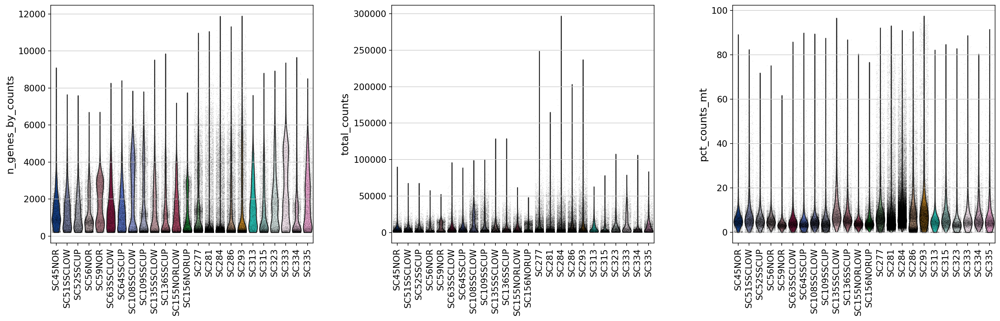

In [36]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)

sc.pl.violin(adata_merged,
    ["n_genes_by_counts","total_counts", "pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

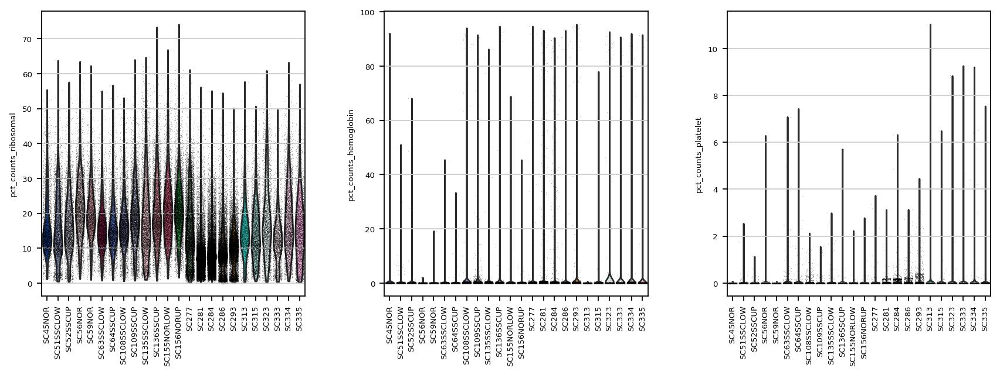

In [37]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)
sc.set_figure_params(scanpy=True, fontsize=6)

sc.pl.violin(adata_merged,
    ["pct_counts_ribosomal", "pct_counts_hemoglobin","pct_counts_platelet"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=False,
    size = 0.2 )  # 3 inches per row)  # width x height in inches)

In [38]:
adata_merged.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,supplementary_file_4,supplementary_file_5,supplementary_file_6,supplementary_file_7,supplementary_file_8,supplementary_file_9,age:ch1,disease_status:ch1,patientcorecode:ch1,Sex:ch1
cell,,,,,,,,,,,,,,,,,,,,,
SC109SSCUP_AAACCTGAGACAGACC-1-SC109SSCUP-GSE128169,214,SC109SSCUP,347.0,214,25.072047,16.138329,0.000000,0.0,1.621495,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SC109SSCUP_AAACCTGAGCACCGCT-1-SC109SSCUP-GSE128169,1814,SC109SSCUP,6536.0,1814,4.345165,22.995716,0.000000,0.0,3.603087,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SC109SSCUP_AAACCTGCAAGCCGTC-1-SC109SSCUP-GSE128169,6447,SC109SSCUP,69041.0,6447,4.759491,14.504425,0.021726,0.0,10.709012,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SC109SSCUP_AAACCTGCAAGTTGTC-1-SC109SSCUP-GSE128169,3219,SC109SSCUP,19483.0,3219,7.042037,12.369758,0.010265,0.0,6.052501,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SC109SSCUP_AAACCTGCACACATGT-1-SC109SSCUP-GSE128169,888,SC109SSCUP,2937.0,888,9.635682,2.110998,0.000000,0.0,3.307432,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SC313_TTTGTCACATCATCCC-1-GSE212109,1720,SC313,5284.0,1720,4.258138,15.972748,0.000000,0.0,3.072093,GSE212109,...,nan,nan,nan,nan,nan,nan,NaN,nan,nan,nan
SC313_TTTGTCACATTTGCTT-1-GSE212109,472,SC313,1220.0,472,2.131147,19.344263,0.000000,0.0,2.584746,GSE212109,...,nan,nan,nan,nan,nan,nan,NaN,nan,nan,nan
SC313_TTTGTCAGTCTACCTC-1-GSE212109,840,SC313,1883.0,840,8.921933,5.469995,0.053107,0.0,2.241667,GSE212109,...,nan,nan,nan,nan,nan,nan,NaN,nan,nan,nan


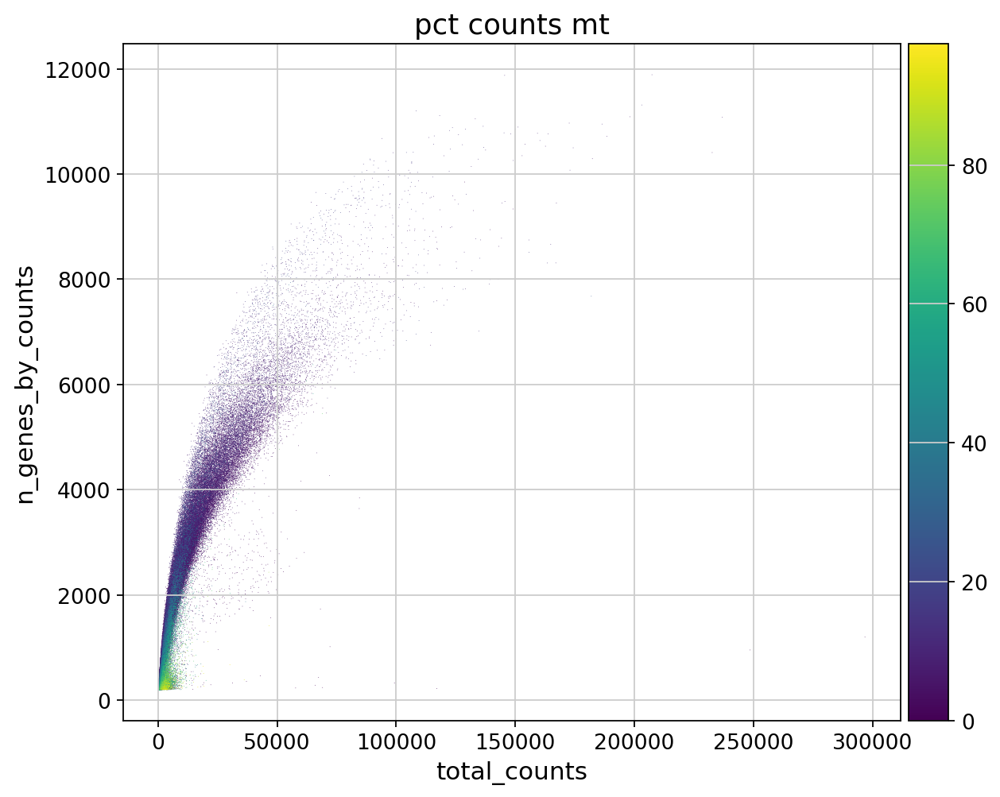

In [39]:
plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

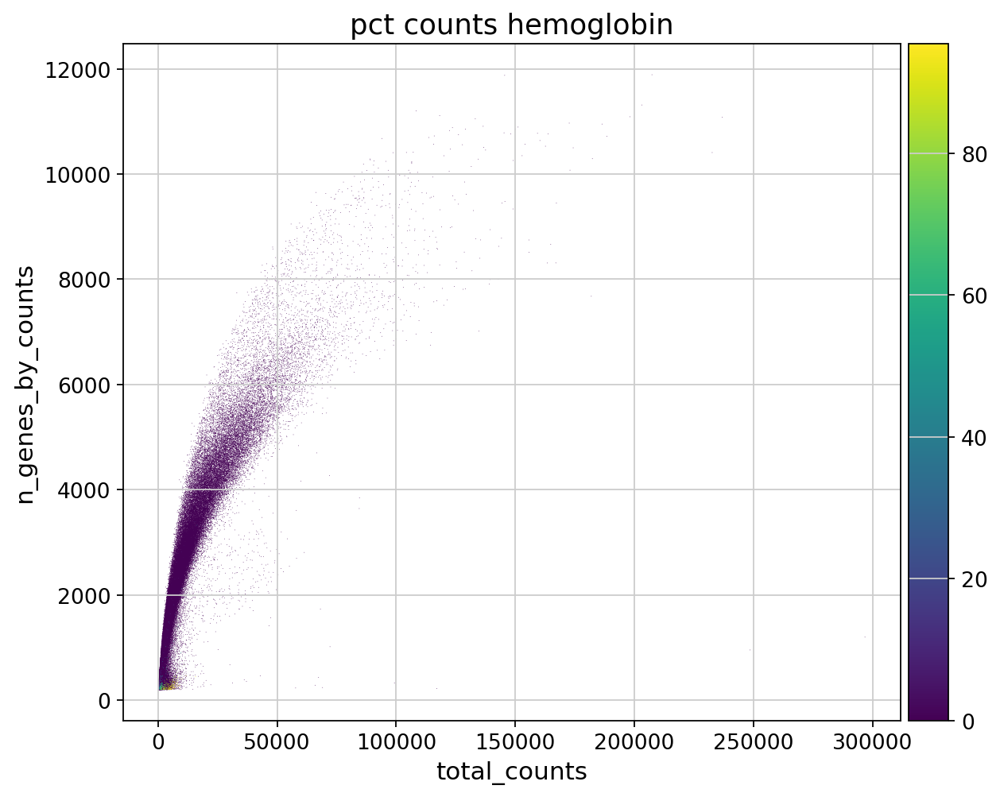

In [40]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_hemoglobin")

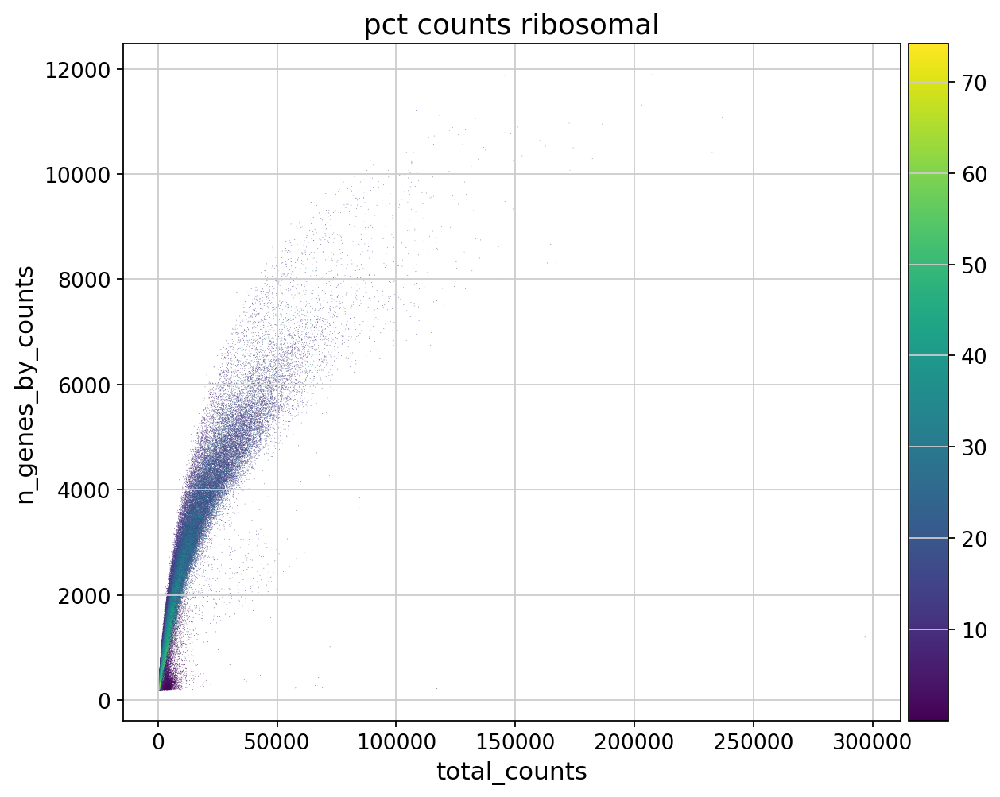

In [41]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_ribosomal")

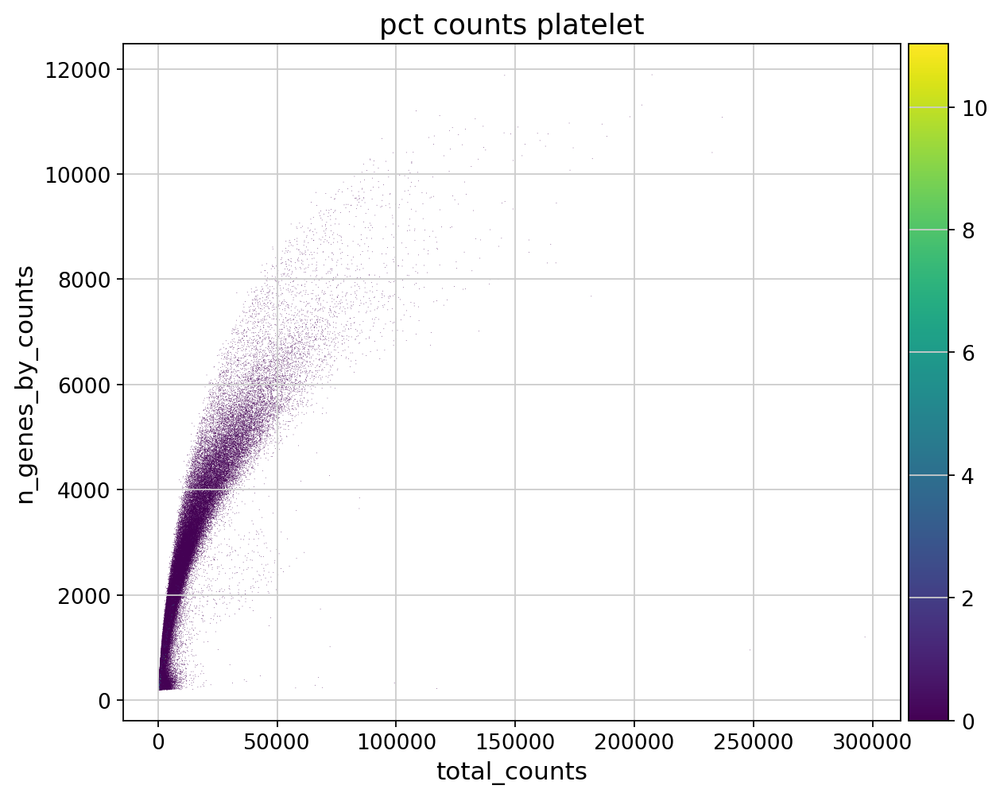

In [42]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_platelet")

In [43]:
print(len(adata_merged.obs))

243814


# FILTERING THRESHOLD EXPLORATION

In [44]:
# Define thresholds for filtering
ribo_thresholds_down = np.arange(0, 15, 2.5)  # Ribosomal % from 0% to 15%
ribo_thresholds_up = np.arange(20, 50, 5)  # Ribosomal % from 20% to 60%
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
243814


In [45]:
for ribo_down in ribo_thresholds_down:
    for ribo_up in ribo_thresholds_up:
        num_cells_removed = ((adata_merged.obs["pct_counts_ribosomal"] > ribo_down) & 
                             (adata_merged.obs["pct_counts_ribosomal"] < ribo_up)).sum()
        results.append([ribo_down, ribo_up, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Ribo_Threshold down > (%)", "Ribo_Threshold up < (%)", "Cells_Left"])
print(qc_table)

    Ribo_Threshold down > (%)  Ribo_Threshold up < (%)  Cells_Left
0                         0.0                       20      201542
1                         0.0                       25      220912
2                         0.0                       30      232294
3                         0.0                       35      238463
4                         0.0                       40      241335
5                         0.0                       45      242711
6                         2.5                       20      191287
7                         2.5                       25      210657
8                         2.5                       30      222039
9                         2.5                       35      228208
10                        2.5                       40      231080
11                        2.5                       45      232456
12                        5.0                       20      175272
13                        5.0                       25      19

In [46]:
# Define thresholds for filtering
gene_thresholds = np.arange(5000, 9000, 1000)  # Gene Threshold
count_thresholds = np.arange(30000, 70000, 10000)  # Count Threshold
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
243814


In [47]:
for gene in gene_thresholds:
    for count in count_thresholds:
        num_cells_removed = ((adata.obs["total_counts"] < gene) & 
                             (adata.obs["n_genes_by_counts"] < count)).sum()
        results.append([gene, count, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Gene number < (%)", "Reads/UMI counts < (%)", "Cells_Left"])
print(qc_table)

    Gene number < (%)  Reads/UMI counts < (%)  Cells_Left
0                5000                   30000      138256
1                5000                   40000      138256
2                5000                   50000      138256
3                5000                   60000      138256
4                6000                   30000      141331
5                6000                   40000      141331
6                6000                   50000      141331
7                6000                   60000      141331
8                7000                   30000      143643
9                7000                   40000      143643
10               7000                   50000      143643
11               7000                   60000      143643
12               8000                   30000      145793
13               8000                   40000      145793
14               8000                   50000      145793
15               8000                   60000      145793


In [48]:
# Define thresholds for filtering
mito_thresholds = np.arange(5, 25, 5)  # Ribosomal % from 2.5% to 15%
hemo_thresholds = np.arange(0.5, 2.0, 0.5)  # Hemoglobin % from 0.25% to 1.5%
plat_thresholds = np.arange(0.5, 2.0, 0.5)  # Platelets % from 0.25% to 1.5%
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
243814


In [49]:
for mito in mito_thresholds:
    for hemo in hemo_thresholds:
        for plat in plat_thresholds:
            num_cells_removed = ((adata_merged.obs["pct_counts_mt"] < mito) & 
                                 (adata_merged.obs["pct_counts_hemoglobin"] < hemo) &
                                 (adata_merged.obs["pct_counts_platelet"] < plat)).sum()
            results.append([mito, hemo, plat, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Mito_Thr < (%)", "Hemo_Thr < (%)", "Plat_Thr < (%)", "Cells_Left"])
print(qc_table)

    Mito_Thr < (%)  Hemo_Thr < (%)  Plat_Thr < (%)  Cells_Left
0                5             0.5             0.5      104232
1                5             0.5             1.0      104275
2                5             0.5             1.5      104293
3                5             1.0             0.5      104895
4                5             1.0             1.0      104938
5                5             1.0             1.5      104956
6                5             1.5             0.5      104949
7                5             1.5             1.0      104992
8                5             1.5             1.5      105010
9               10             0.5             0.5      181320
10              10             0.5             1.0      181418
11              10             0.5             1.5      181462
12              10             1.0             0.5      182259
13              10             1.0             1.0      182357
14              10             1.0             1.5     

# FILTERING STEP (Harmonized with Celina)
## UMI > 200
## Removal genes with < 10 total reads
## % mitocondrial removal after 95th percentile, il less than 20%, 20% filtering by default
## % Gene number and UMI removal after the 99th percentile

In [50]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)
sc.set_figure_params(scanpy=True, fontsize=6)

print("Prefilter number of cells")
print(len(adata_merged.obs))

Prefilter number of cells
243814


In [51]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "total_counts",
    low_base: float = 200,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Fixed filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Manual modification to apply a fixed threshold ---
    low_cutoff = 200
    # --- Apply filtering ---
    mask = adata.obs[feature] >= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


  • Cells kept: 243814
  • Cells removed: 0


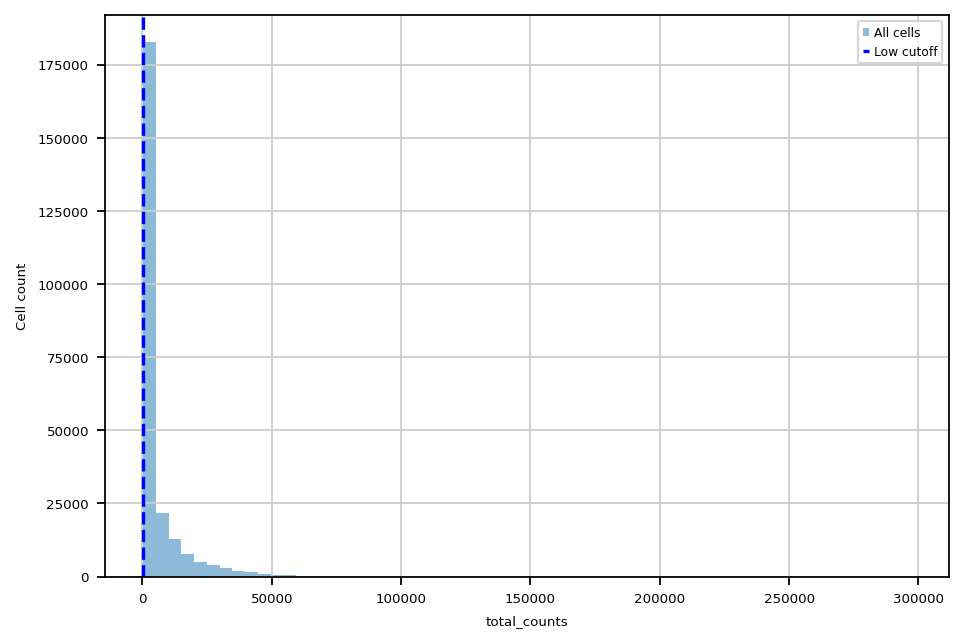


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 0 cells

Filtered cells:


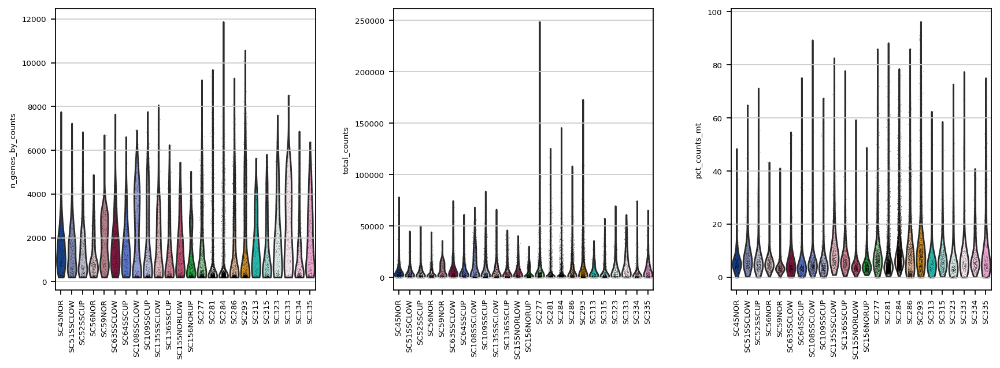

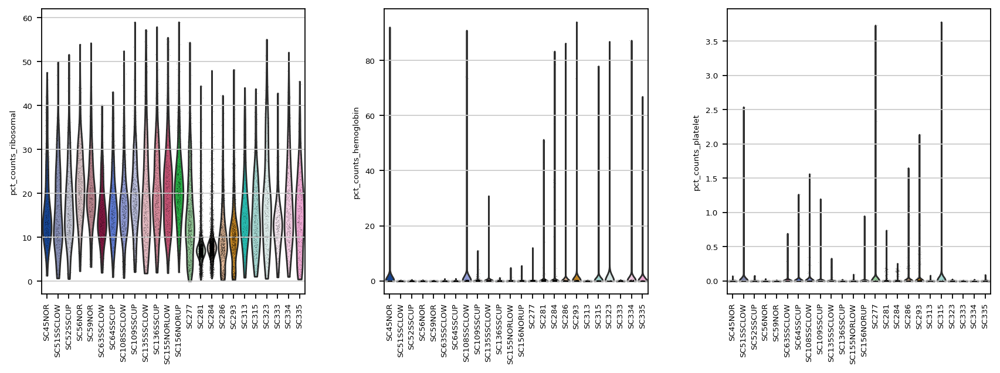


Removed cells:


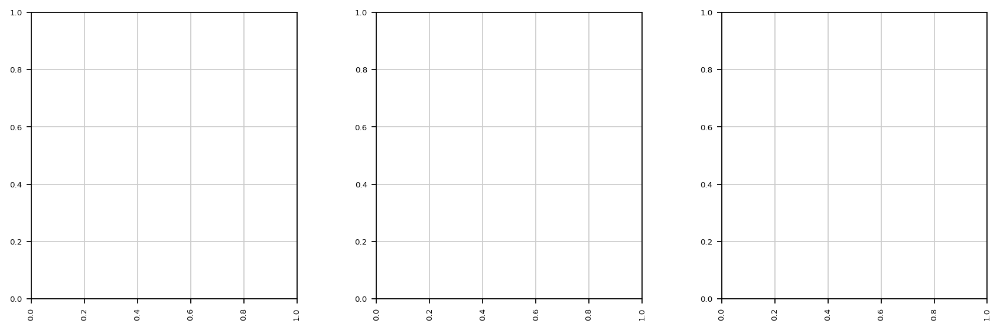

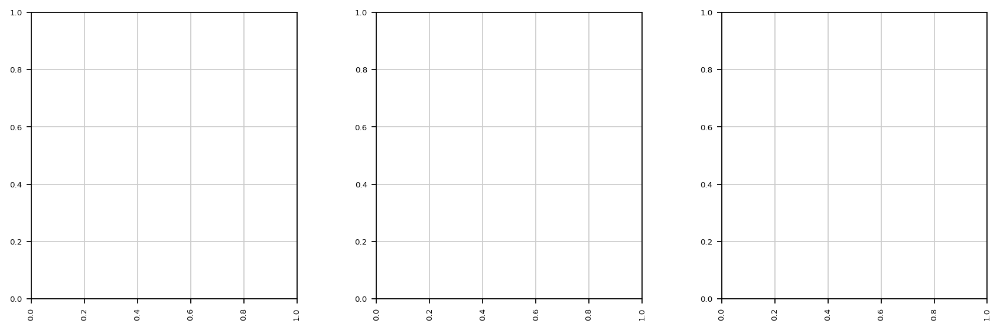

In [52]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="total_counts",
    low_base=200,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


In [53]:
adata
values = adata.obs["total_counts"].dropna()
low_perc = np.percentile(values, 100 - 1)
print(low_perc)

52540.75


In [54]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "total_counts",
    tail_trim: float = 1,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Adaptive filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Compute baseline (percentile and fraction below threshold) ---
    low_cutoff = np.percentile(values, 100 - tail_trim)
    

    print(f"Adaptive gene filtering summary:")
    print(f"  • Initial number of cells: {adata.n_obs}")
    print(f"  • Percentile baseline (low): {tail_trim}%")

    # --- Apply filtering ---
    mask = adata.obs[feature] <= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


Adaptive gene filtering summary:
  • Initial number of cells: 243814
  • Percentile baseline (low): 1%
  • Cells kept: 241375
  • Cells removed: 2439


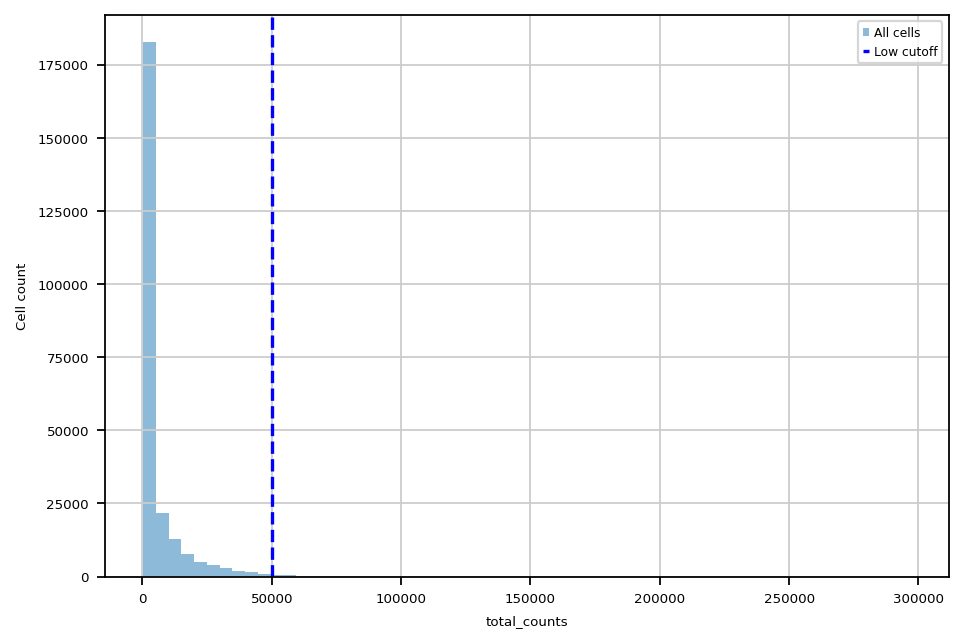


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 2439 cells

Filtered cells:


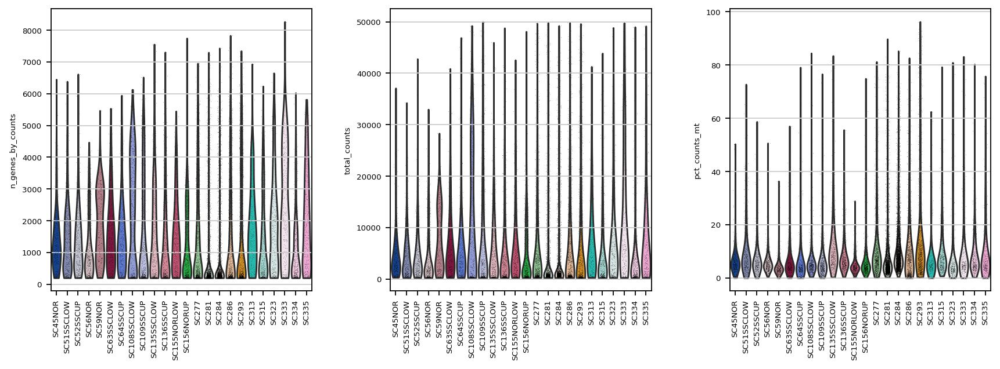

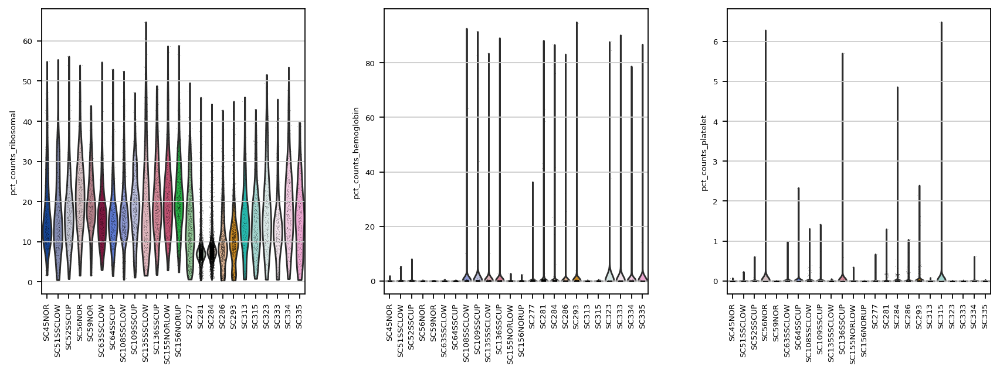


Removed cells:


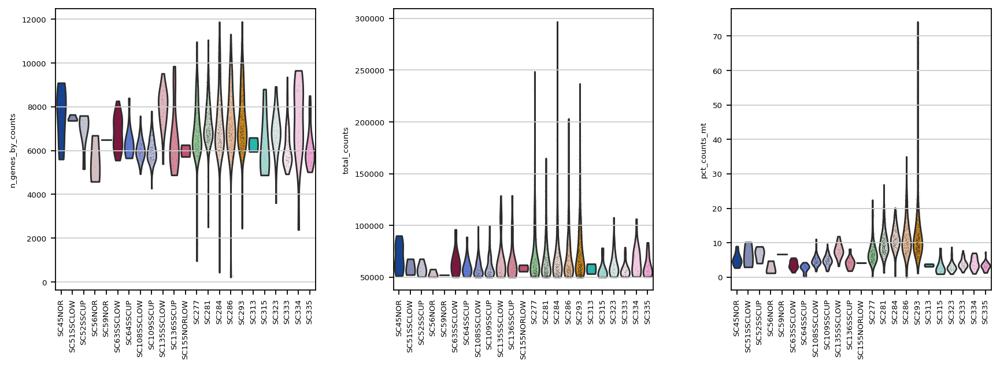

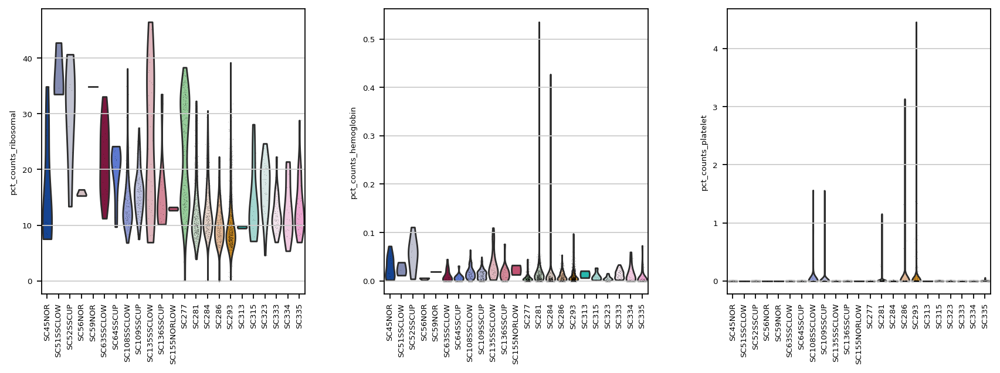

In [55]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="total_counts",
    tail_trim=1,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


Adaptive gene filtering summary:
  • Initial number of cells: 241375
  • Percentile baseline (low): 1%
  • Cells kept: 238964
  • Cells removed: 2411


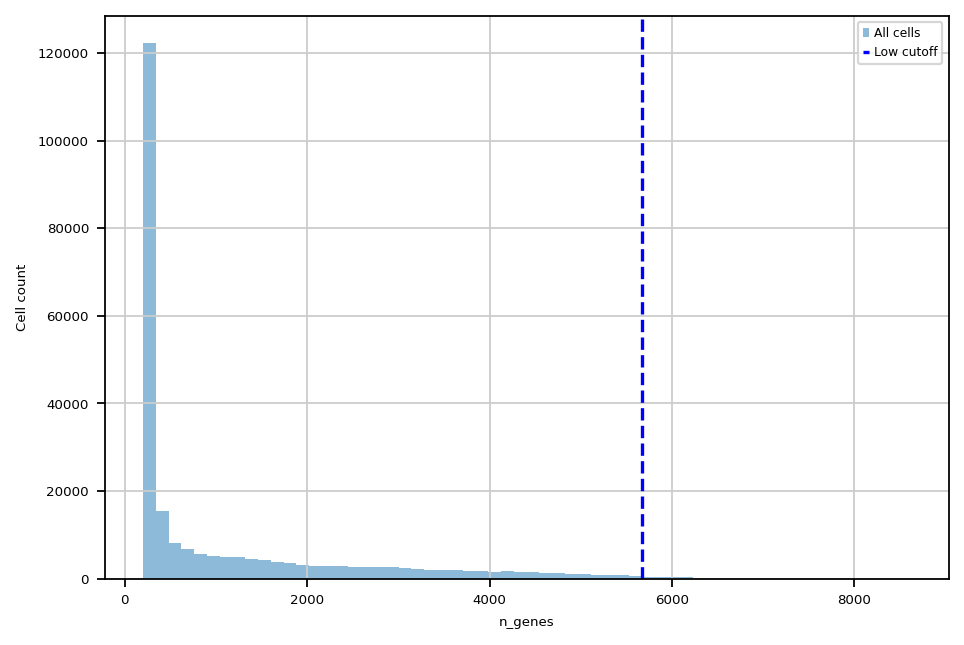


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 2411 cells

Filtered cells:


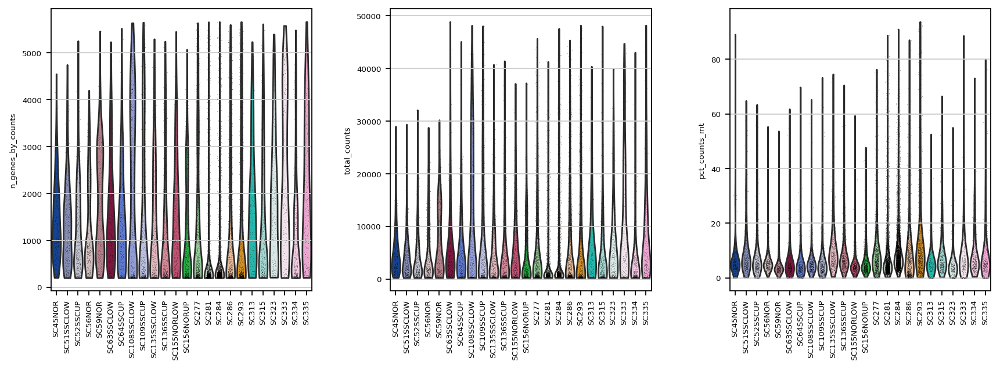

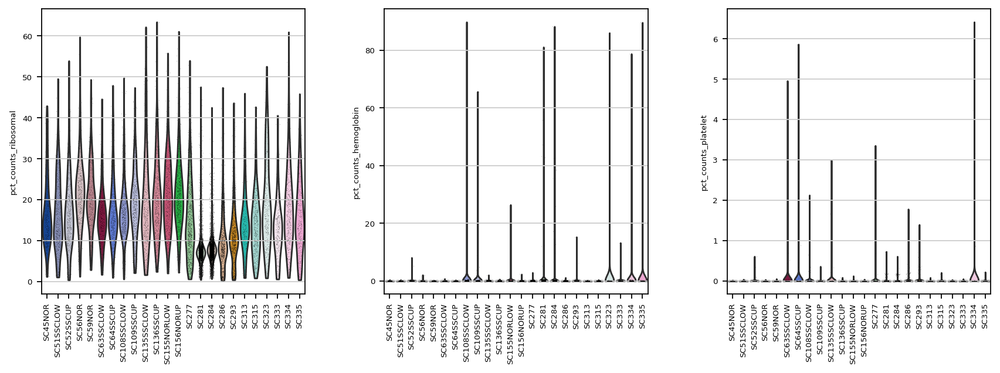


Removed cells:


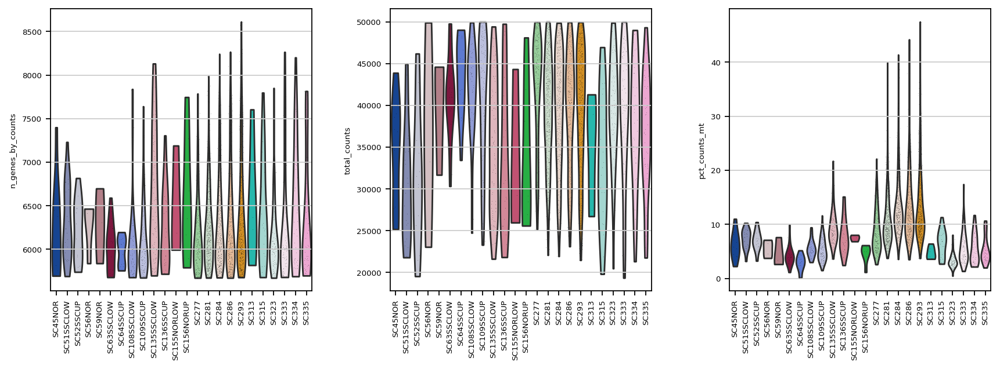

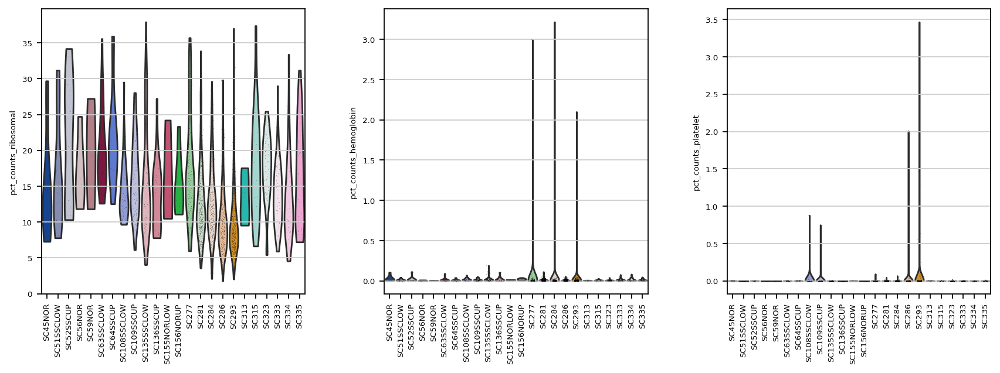

In [56]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="n_genes",
    tail_trim=1,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)

In [57]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "pct_counts_mt",
    low_base: float = 20,
    tail_trim: float = 5,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Adaptive filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Compute baseline (percentile and fraction below threshold) ---
    low_perc = np.percentile(values, 100 - tail_trim)

    if low_perc < low_base:
        low_cutoff = low_base
    else:
        low_cutoff = low_perc
    

    print(f"Adaptive gene filtering summary:")
    print(f"  • Initial number of cells: {adata.n_obs}")
    print(f"  • Percentile baseline (low): {tail_trim}%")
    print(f"  • Percentile threshold: {low_perc}%")
    print(f"  • Chosen threshold: {low_cutoff}%")

    # --- Apply filtering ---
    mask = adata.obs[feature] <= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


Adaptive gene filtering summary:
  • Initial number of cells: 238964
  • Percentile baseline (low): 5%
  • Percentile threshold: 34.55636739730835%
  • Chosen threshold: 34.55636739730835%
  • Cells kept: 227015
  • Cells removed: 11949


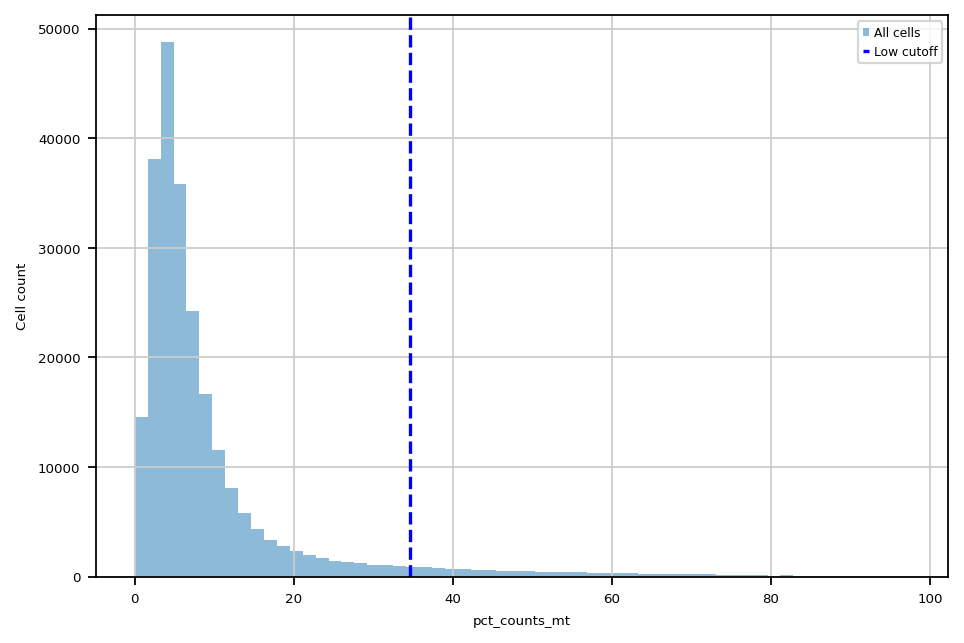


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 11949 cells

Filtered cells:


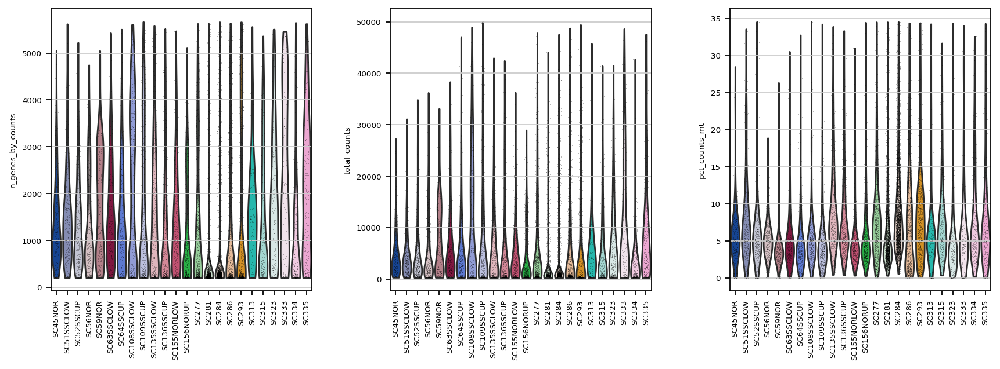

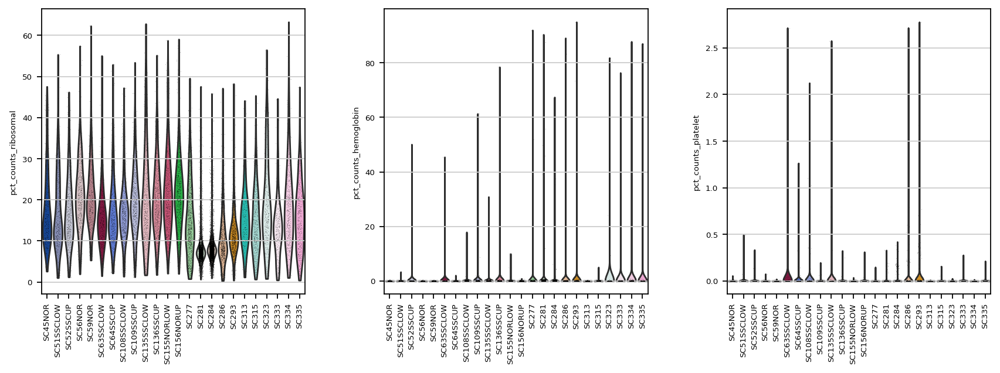


Removed cells:


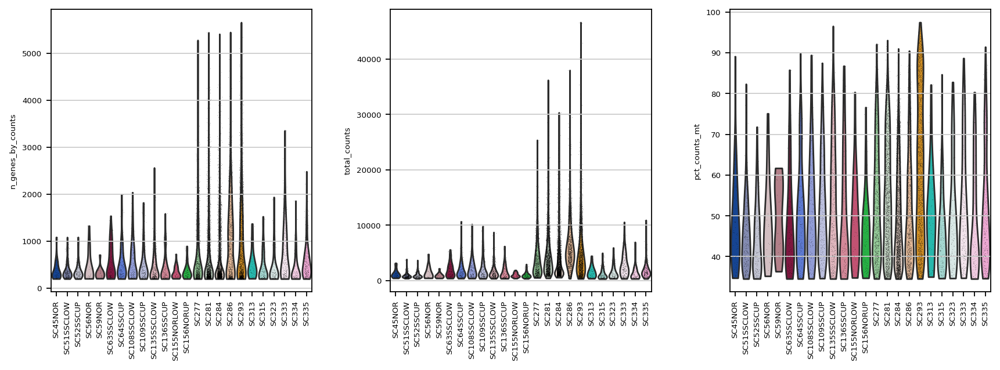

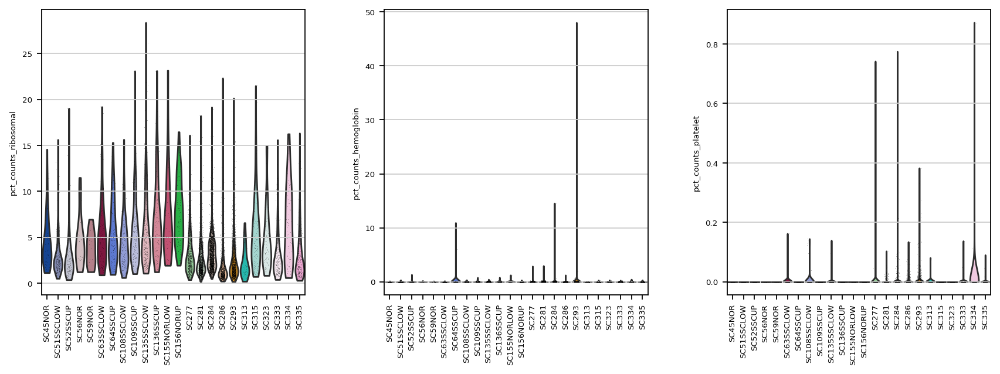

In [58]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="pct_counts_mt",
    low_base=20,
    tail_trim=5,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


In [59]:
import scanpy as sc
import numpy as np

print(f"Genes before: {adata_merged.n_vars}")

# Calcola il totale delle reads per gene (somma su tutte le cellule)
gene_counts = np.array(adata_merged.X.sum(axis=0)).flatten()

# Crea una maschera booleana: True per i geni con >= 10 reads
gene_mask = gene_counts >= 10

# Filtra l'AnnData
adata_merged = adata_merged[:, gene_mask].copy()

print(f"Genes after: {adata_merged.n_vars}")

Genes before: 21934
Genes after: 18738


# After Filtering and clustering

In [60]:
adata_merged.raw = adata_merged.copy()
sc.pp.normalize_total(adata_merged, target_sum=1e4)
print(adata_merged.raw.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 234330068 stored elements and shape (227015, 18738)>
  Coords	Values
  (0, 18725)	8.0
  (0, 18722)	8.0
  (0, 18720)	4.0
  (0, 18719)	23.0
  (0, 18718)	15.0
  (0, 18716)	3.0
  (0, 18715)	13.0
  (0, 18714)	7.0
  (0, 18713)	6.0
  (0, 18695)	1.0
  (0, 18361)	2.0
  (0, 18180)	1.0
  (0, 18170)	1.0
  (0, 18089)	1.0
  (0, 17916)	1.0
  (0, 17850)	1.0
  (0, 17761)	1.0
  (0, 17705)	5.0
  (0, 17620)	1.0
  (0, 17588)	1.0
  (0, 17518)	2.0
  (0, 17074)	1.0
  (0, 17064)	1.0
  (0, 16950)	2.0
  (0, 16533)	1.0
  :	:
  (227014, 8352)	3.0
  (227014, 8353)	3.0
  (227014, 8355)	1.0
  (227014, 8358)	1.0
  (227014, 8359)	2.0
  (227014, 8360)	3.0
  (227014, 8369)	3.0
  (227014, 8372)	1.0
  (227014, 8373)	1.0
  (227014, 18019)	6.0
  (227014, 18020)	2.0
  (227014, 18026)	2.0
  (227014, 18713)	44.0
  (227014, 18714)	21.0
  (227014, 18715)	86.0
  (227014, 18716)	64.0
  (227014, 18717)	3.0
  (227014, 18718)	109.0
  (227014, 18719)	47.0
  (227014, 18720)	4

In [61]:
import re

print(f"Original genes: {adata_merged.n_vars}")

# Keep genes that do NOT match the pattern: ends with .digit
pattern = re.compile(r".*\.\d+$")
removed_dot  = [gene for gene in adata_merged.var_names if pattern.match(gene)]
keep_genes = [not pattern.match(gene) for gene in adata_merged.var_names]

print(f"\nGeni rimossi per pattern '.digit' ({len(removed_dot)}):")
print(removed_dot)

# Subset the AnnData object
adata2 = adata_merged[:, keep_genes].copy()

print(f"Filtered genes: {adata2.n_vars}")

Original genes: 18738

Geni rimossi per pattern '.digit' (305):
['AP006222.2', 'AL645728.1', 'AC253572.1', 'AC245100.1', 'AL450992.2', 'AL589986.2', 'AC234582.2', 'AC234582.1', 'AL365181.2', 'AL591806.1', 'AC093326.1', 'AC092159.2', 'AC144450.1', 'AC093390.1', 'AC010907.2', 'AC107057.1', 'AC092580.4', 'AC010969.1', 'AC092687.3', 'AC062028.1', 'AC099344.3', 'AC008278.2', 'AC010096.1', 'AC012065.4', 'AC011752.1', 'AC018742.1', 'AC012506.4', 'AC011239.1', 'AC009228.1', 'AC104699.1', 'AC093690.1', 'AC104695.4', 'AC109642.1', 'AC007391.2', 'AC006369.2', 'AC083949.1', 'AC093702.1', 'AC007743.1', 'AC093159.1', 'AC007098.1', 'AC012368.1', 'AC007365.1', 'AC007880.1', 'AC133644.2', 'AC062029.1', 'AC103563.9', 'AC008268.1', 'AC159540.1', 'AC159540.2', 'AC010884.1', 'AC068491.2', 'AC017002.1', 'AC017002.2', 'AC017074.1', 'AC104653.1', 'AC009312.1', 'AC073257.2', 'AC073257.1', 'AC010976.2', 'AJ239322.1', 'AC097532.2', 'AC114763.1', 'AC092652.1', 'AC016910.1', 'AC092484.1', 'AC105402.4', 'AC007364.1

In [62]:
cite_genes = adata.var_names[adata.var_names.str.contains("CITE", case=False, na=False)]
print(cite_genes)

Index(['CD14-CITE', 'CD14-M5E2-CITE', 'CD163-CITE', 'CD1C-CITE', 'CD207-CITE',
       'CD209-CITE', 'CD34-CITE', 'CD55-CITE', 'CDH11-CITE', 'CITED1',
       'CITED2', 'CITED4', 'DPP4-CITE', 'EPCAM-CITE', 'FCER1A-CITE',
       'FCGR3A-CITE', 'IL3RA-CITE', 'MCAM-CITE', 'PDGFRA-CITE', 'PDGFRB-CITE',
       'PDPN-CITE', 'SIGLEC1-CITE', 'THBD-CITE', 'THY1-CITE'],
      dtype='object')


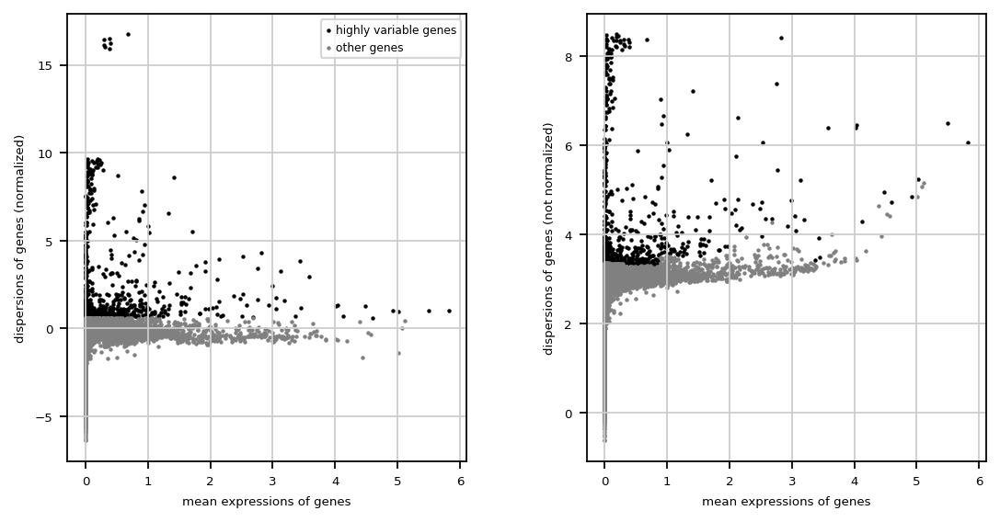

In [63]:
sc.pp.log1p(adata2)
sc.pp.highly_variable_genes(adata2, n_top_genes=1000)
#sc.pp.highly_variable_genes(adata2, min_mean=0.0125, max_mean=3, min_disp=0.5, n_top_genes=1000)
sc.pl.highly_variable_genes(adata2)

In [64]:
hv_genes = adata2.var.highly_variable
print(hv_genes)
adata_hv = adata2[:, hv_genes].copy()

FAM87B       False
LINC00115    False
FAM41C       False
SAMD11       False
NOC2L        False
             ...  
MT-ND4L       True
MT-ND4       False
MT-ND5       False
MT-ND6        True
MT-CYB        True
Name: highly_variable, Length: 18433, dtype: bool


In [65]:
import numpy as np
import skimage

# Run Scrublet
sc.pp.scrublet(adata_hv, use_approx_neighbors=True, sim_doublet_ratio=1, n_neighbors=10, n_prin_comps=5 )

print("predicted doublets")
print(adata_hv.obs['predicted_doublet'].sum())  # conta i True direttamente

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/legacy_api_wrap/__init__.py:82: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


predicted doublets
2499


cell
SC109SSCUP_AAACCTGAGACAGACC-1-SC109SSCUP-GSE128169    0.029197
SC109SSCUP_AAACCTGAGCACCGCT-1-SC109SSCUP-GSE128169    0.015244
SC109SSCUP_AAACCTGCAAGTTGTC-1-SC109SSCUP-GSE128169    0.019355
SC109SSCUP_AAACCTGCACACATGT-1-SC109SSCUP-GSE128169    0.059406
SC109SSCUP_AAACCTGCACAGACAG-1-SC109SSCUP-GSE128169    0.059406
                                                        ...   
SC313_TTTGTCACATCATCCC-1-GSE212109                    0.050000
SC313_TTTGTCACATTTGCTT-1-GSE212109                    0.008242
SC313_TTTGTCAGTCTACCTC-1-GSE212109                    0.050000
SC313_TTTGTCATCAGAGCTT-1-GSE212109                    0.005236
SC313_TTTGTCATCTTATCTG-1-GSE212109                    0.015244
Name: doublet_score, Length: 227015, dtype: float64
cell
SC109SSCUP_AAACCTGAGACAGACC-1-SC109SSCUP-GSE128169    False
SC109SSCUP_AAACCTGAGCACCGCT-1-SC109SSCUP-GSE128169    False
SC109SSCUP_AAACCTGCAAGTTGTC-1-SC109SSCUP-GSE128169    False
SC109SSCUP_AAACCTGCACACATGT-1-SC109SSCUP-GSE128169    False
SC109

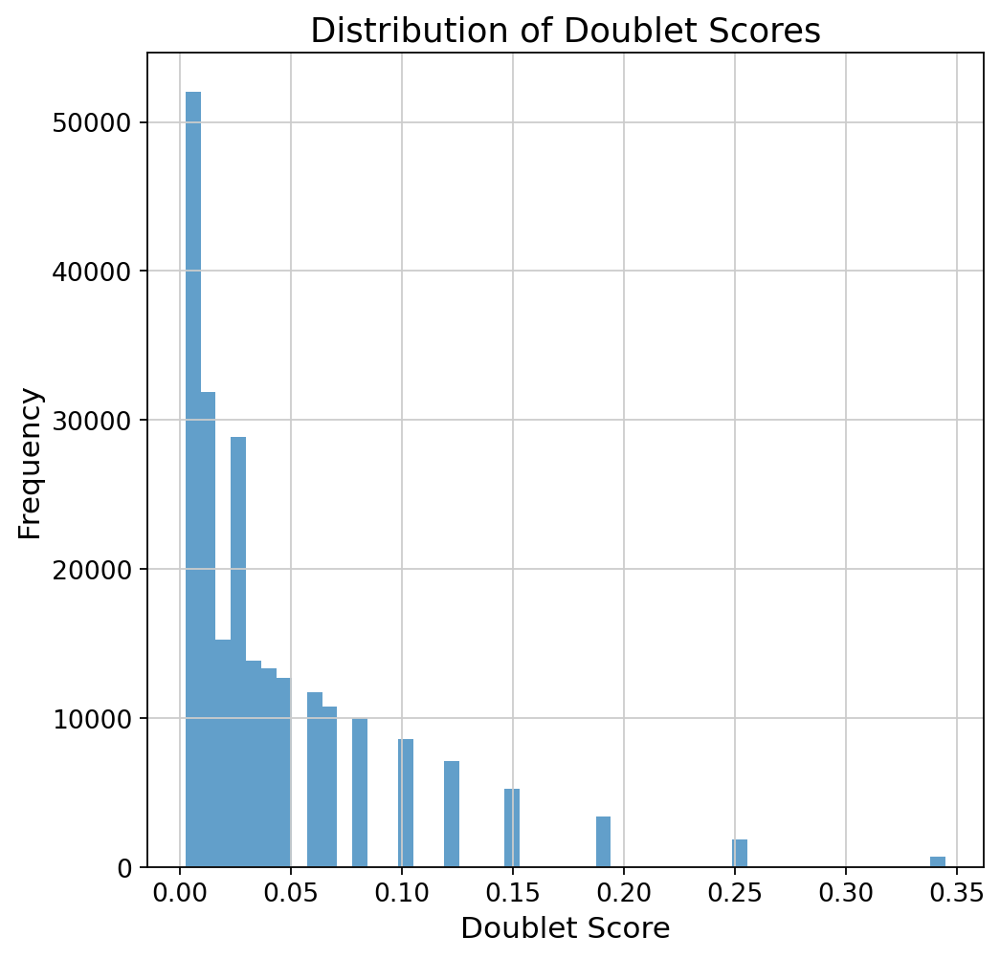

In [66]:
import matplotlib.pyplot as plt


plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size

# Scrublet results are stored in the AnnData object
# Doublet scores
print(adata_hv.obs['doublet_score'])
# Predicted doublets
print(adata_hv.obs['predicted_doublet'])

# Histogram of doublet scores
adata_hv.obs['doublet_score'].plot.hist(bins=50, alpha=0.7)
plt.xlabel('Doublet Score')
plt.ylabel('Frequency')
plt.title('Distribution of Doublet Scores')
plt.show()

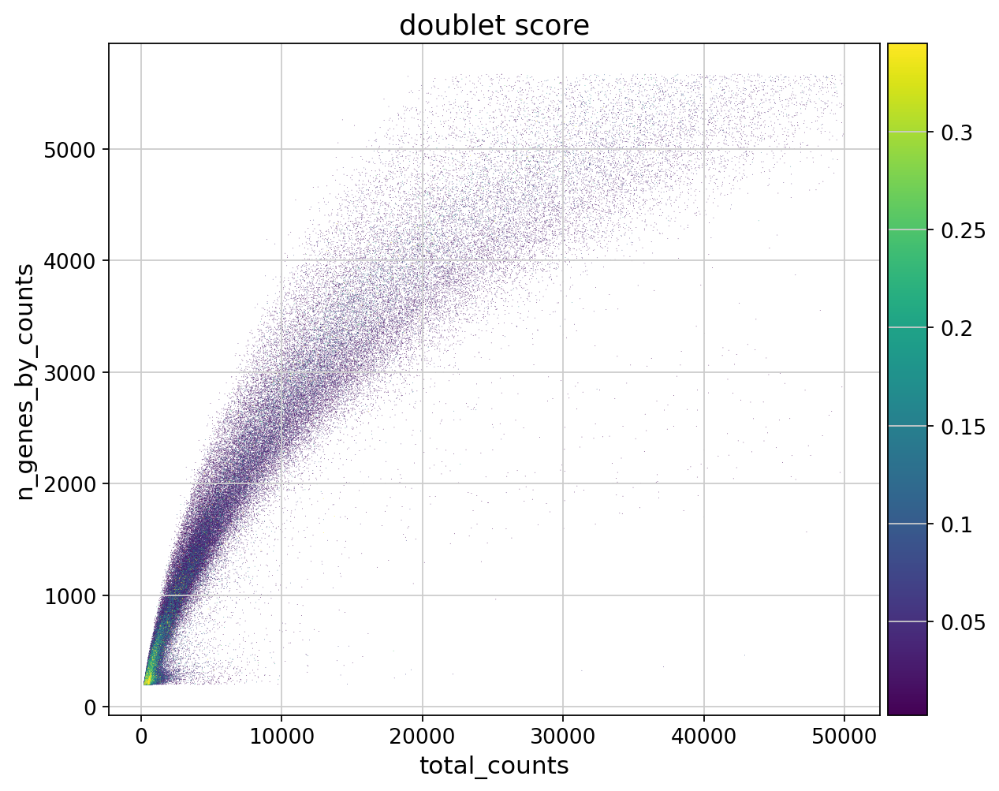

In [67]:
plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size
sc.pl.scatter(adata_hv, x="total_counts", y="n_genes_by_counts", color="doublet_score")

In [68]:
adata_hv.obs['predicted_doublet'] = adata_hv.obs['predicted_doublet'].fillna(False).astype(int)  # 1 = doublet, 0 = singlet

In [69]:
adata3 = adata2
adata3.obs['predicted_doublet'] = adata_hv.obs['predicted_doublet'].copy()
adata3.obs['doublet_score'] = adata_hv.obs['doublet_score'].copy()

print("Number of cells")
print(len(adata3.obs))

Number of cells
227015


In [70]:
adata_removed = adata3[adata3.obs["predicted_doublet"] == 1].copy()
adata3 = adata3[adata3.obs["predicted_doublet"] == 0].copy()

print("Number of cells post doublets")
print(len(adata3.obs))

Number of cells post doublets
224516


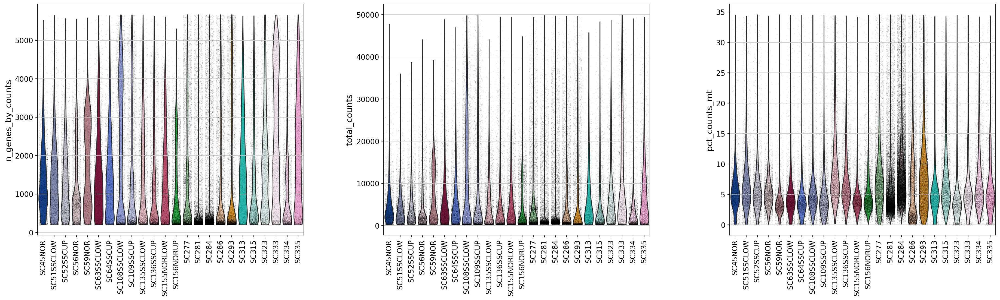

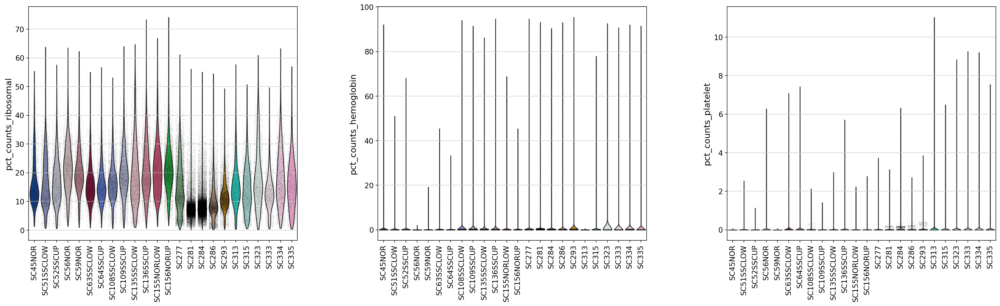

In [71]:
sc.pl.violin(adata3,
    ["n_genes_by_counts", "total_counts","pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)
sc.pl.violin(adata3,
    ["pct_counts_ribosomal","pct_counts_hemoglobin","pct_counts_platelet" ],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

Cells removed
2499


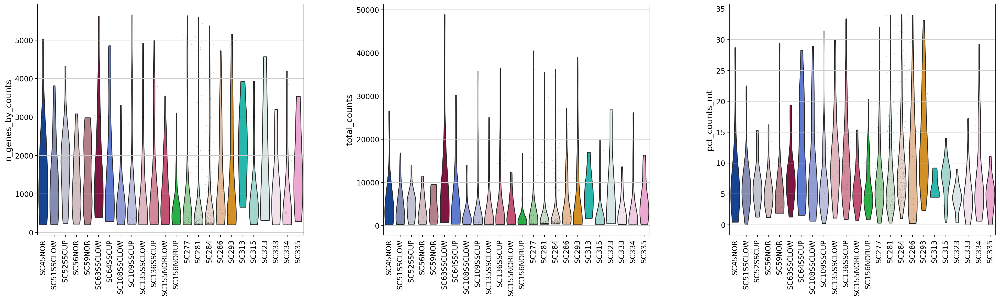

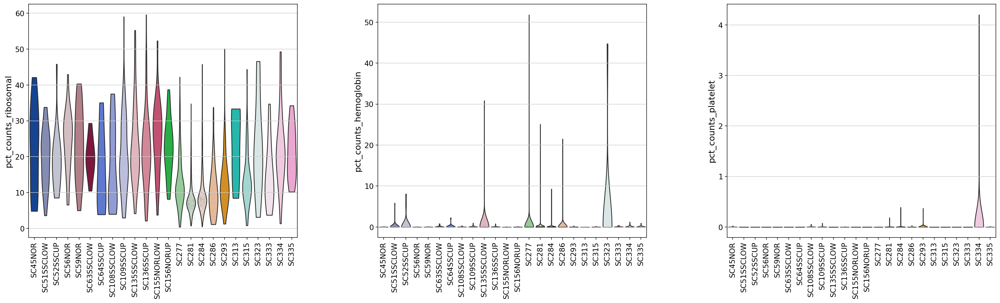

In [72]:
print("Cells removed")
print(len(adata_removed.obs))
sc.pl.violin(adata_removed,
    ["n_genes_by_counts", "total_counts","pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)
sc.pl.violin(adata_removed,
    ["pct_counts_ribosomal","pct_counts_hemoglobin","pct_counts_platelet" ],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

In [73]:
print("Average number of cells per sample")
print(len(adata3.obs)/adata3.obs["sample"].nunique())

Average number of cells per sample
9354.833333333334


In [74]:
adata3.obs["sample"].nunique()

24

In [75]:
import numpy as np

# Quick check
X = adata3.X.toarray() if hasattr(adata3.X, 'toarray') else adata3.X

print(f"Min:  {X.min():.2f}")
print(f"Max:  {X.max():.2f}")
print(f"Mean: {X.mean():.2f}")
print(f"Std:  {X.std():.2f}")

Min:  0.00
Max:  9.11
Mean: 0.08
Std:  0.43


In [76]:
## Scale data
#sc.pp.scale(adata3, max_value=10)
## 

sc.tl.pca(adata3, svd_solver="arpack", use_highly_variable=True)

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


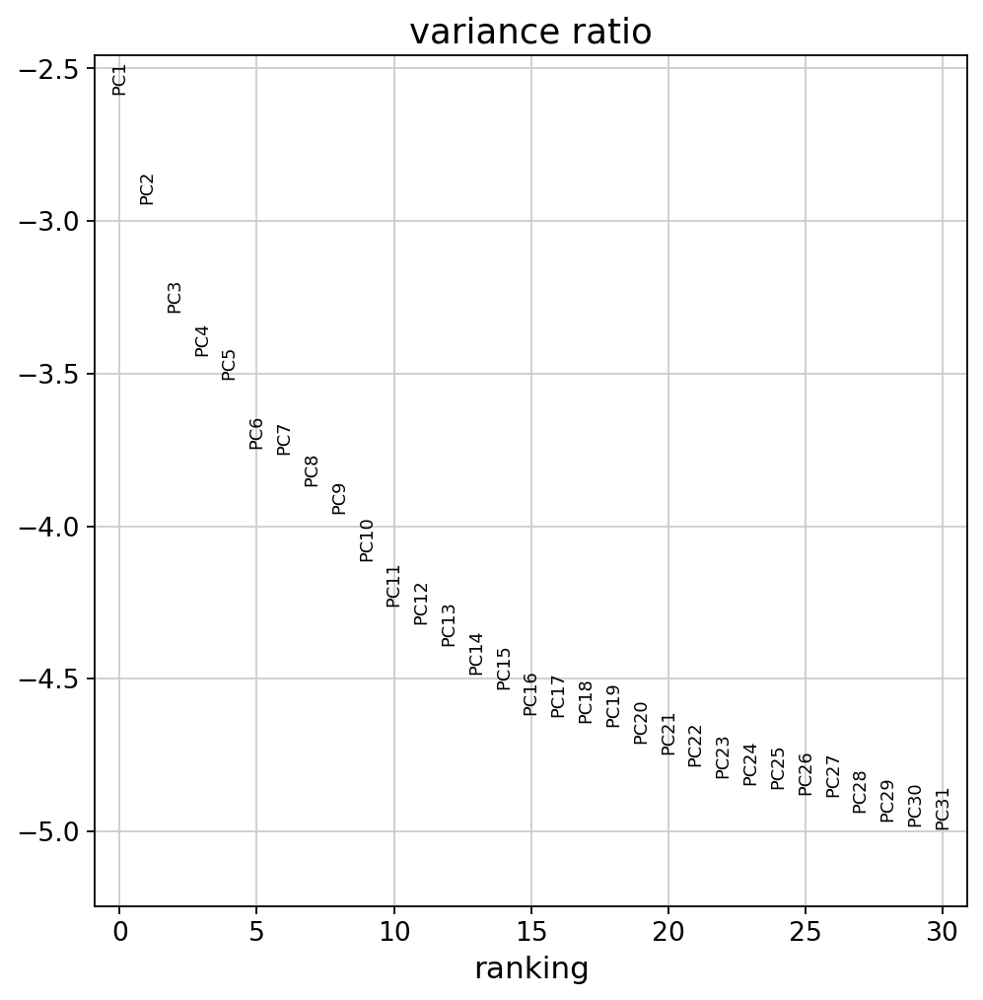

In [77]:
sc.pl.pca_variance_ratio(adata3, log=True)

In [78]:
sc.pp.neighbors(adata3, n_neighbors=15, n_pcs=50)

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [79]:
sc.tl.umap(adata3)

In [80]:
adata3.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,supplementary_file_6,supplementary_file_7,supplementary_file_8,supplementary_file_9,age:ch1,disease_status:ch1,patientcorecode:ch1,Sex:ch1,predicted_doublet,doublet_score
cell,,,,,,,,,,,,,,,,,,,,,
SC109SSCUP_AAACCTGAGACAGACC-1-SC109SSCUP-GSE128169,214,SC109SSCUP,347.0,214,25.072047,16.138329,0.000000,0.0,1.621495,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.029197
SC109SSCUP_AAACCTGAGCACCGCT-1-SC109SSCUP-GSE128169,1814,SC109SSCUP,6536.0,1814,4.345165,22.995716,0.000000,0.0,3.603087,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.015244
SC109SSCUP_AAACCTGCAAGTTGTC-1-SC109SSCUP-GSE128169,3219,SC109SSCUP,19483.0,3219,7.042037,12.369758,0.010265,0.0,6.052501,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.019355
SC109SSCUP_AAACCTGCACACATGT-1-SC109SSCUP-GSE128169,888,SC109SSCUP,2937.0,888,9.635682,2.110998,0.000000,0.0,3.307432,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.059406
SC109SSCUP_AAACCTGCACAGACAG-1-SC109SSCUP-GSE128169,683,SC109SSCUP,1194.0,683,0.753769,2.093802,0.000000,0.0,1.748170,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.059406
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SC313_TTTGTCACATCATCCC-1-GSE212109,1720,SC313,5284.0,1720,4.258138,15.972748,0.000000,0.0,3.072093,GSE212109,...,nan,nan,nan,nan,NaN,nan,nan,nan,0,0.050000
SC313_TTTGTCACATTTGCTT-1-GSE212109,472,SC313,1220.0,472,2.131147,19.344263,0.000000,0.0,2.584746,GSE212109,...,nan,nan,nan,nan,NaN,nan,nan,nan,0,0.008242
SC313_TTTGTCAGTCTACCTC-1-GSE212109,840,SC313,1883.0,840,8.921933,5.469995,0.053107,0.0,2.241667,GSE212109,...,nan,nan,nan,nan,NaN,nan,nan,nan,0,0.050000


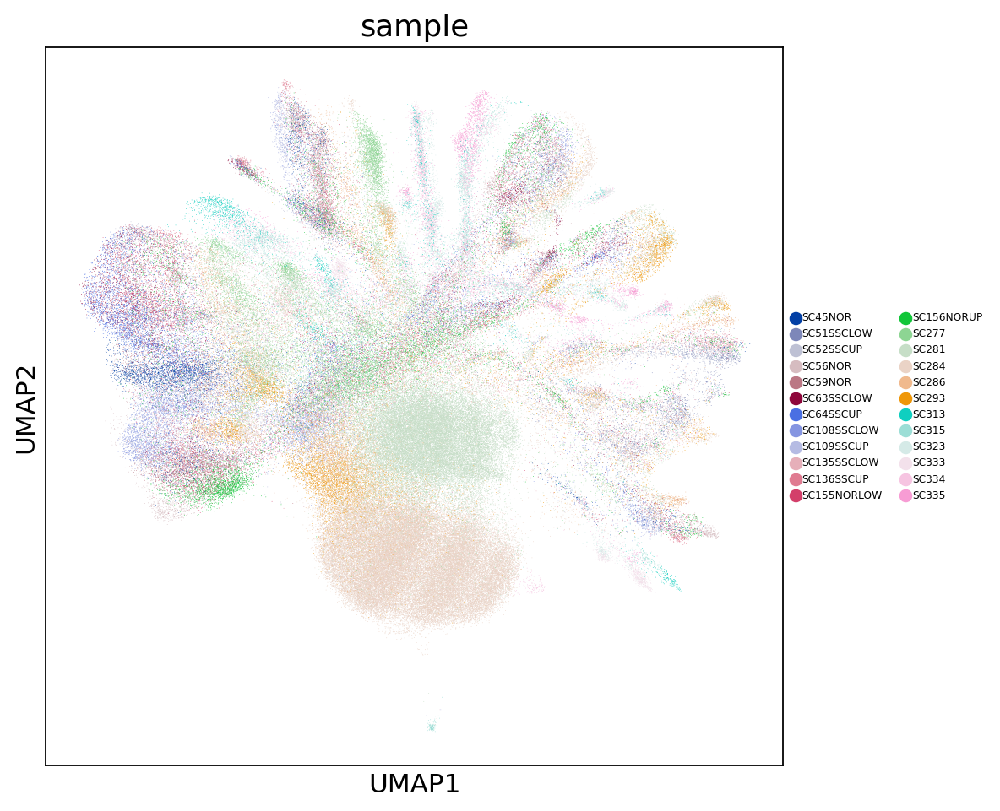

In [81]:
sc.pl.umap(adata3, color=['sample'])

SC109SSCUP


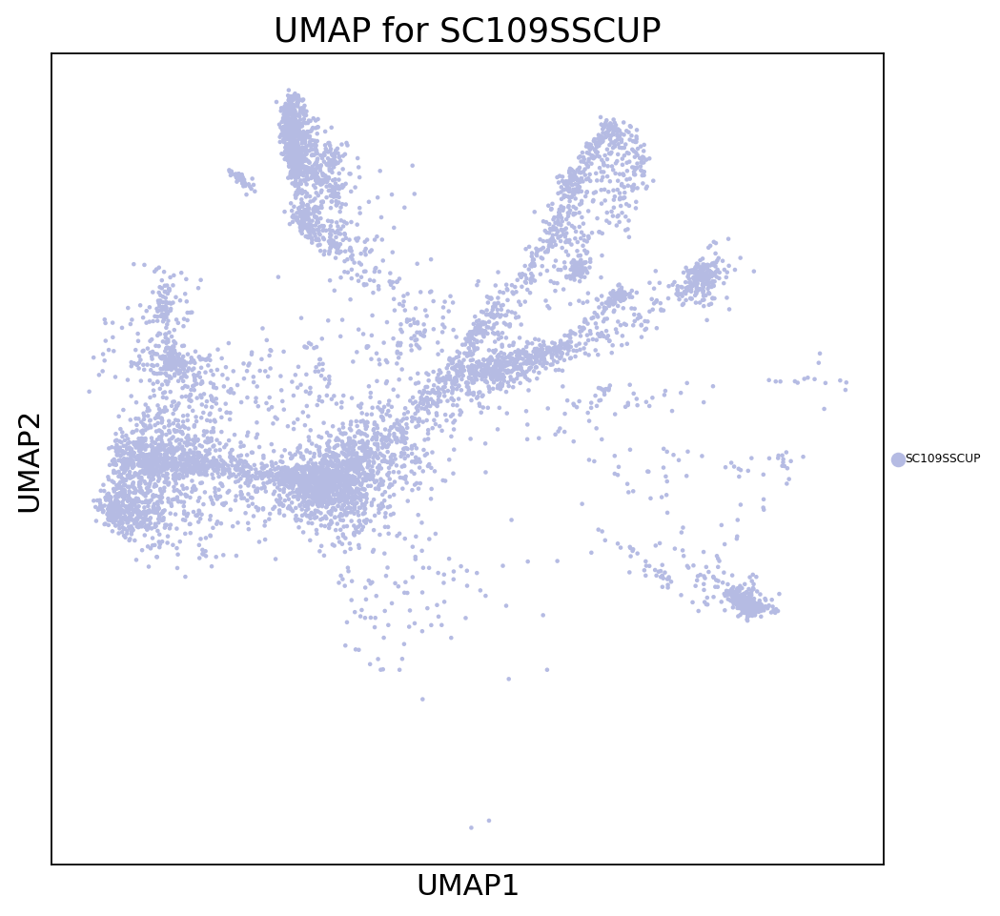

SC155NORLOW


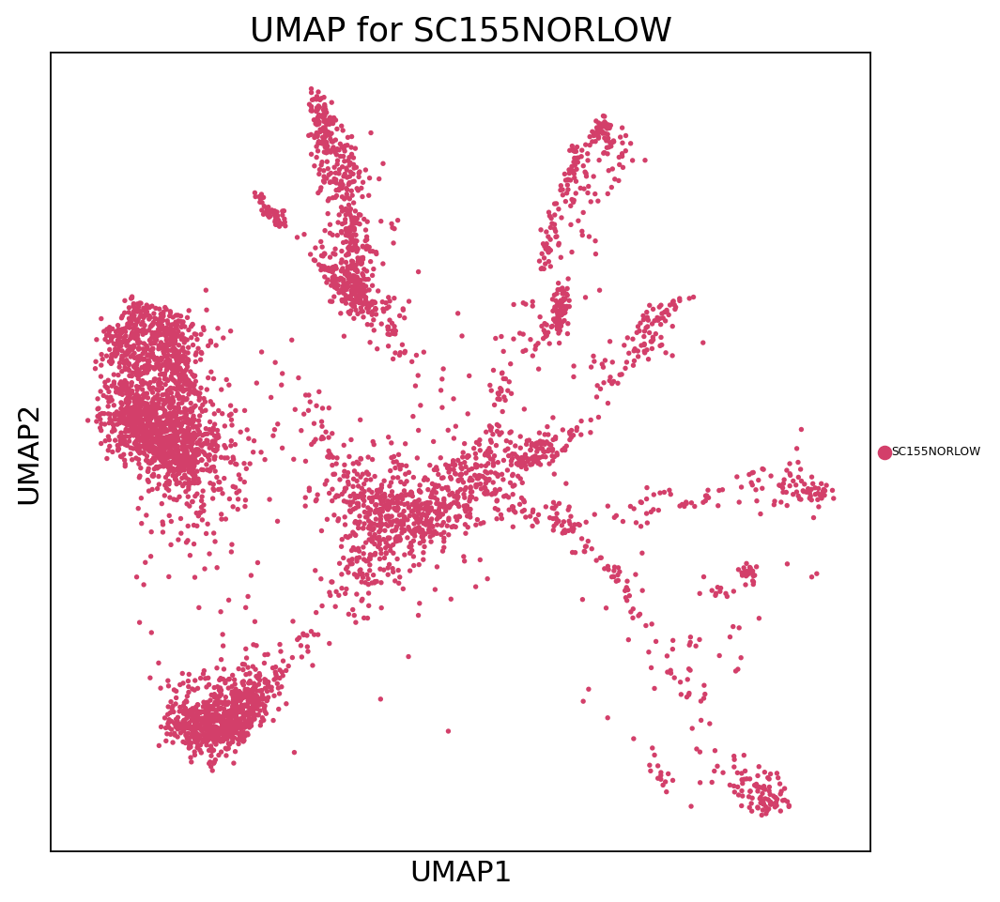

SC51SSCLOW


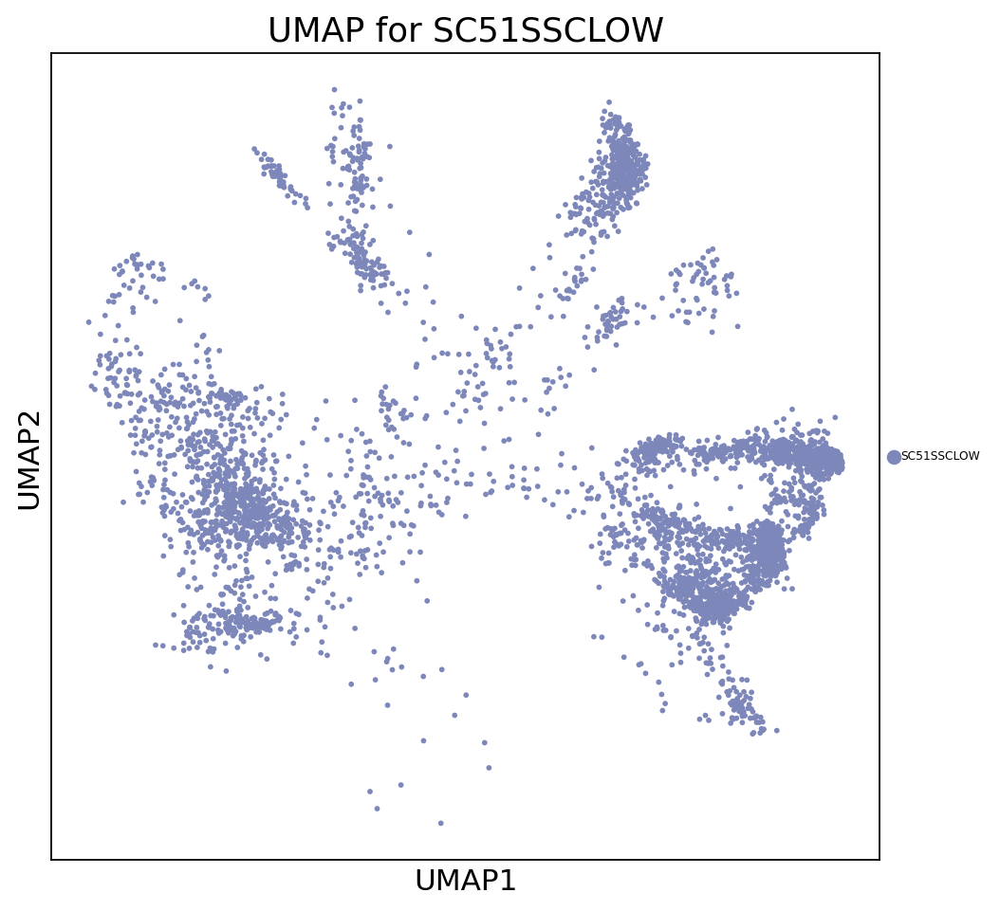

SC52SSCUP


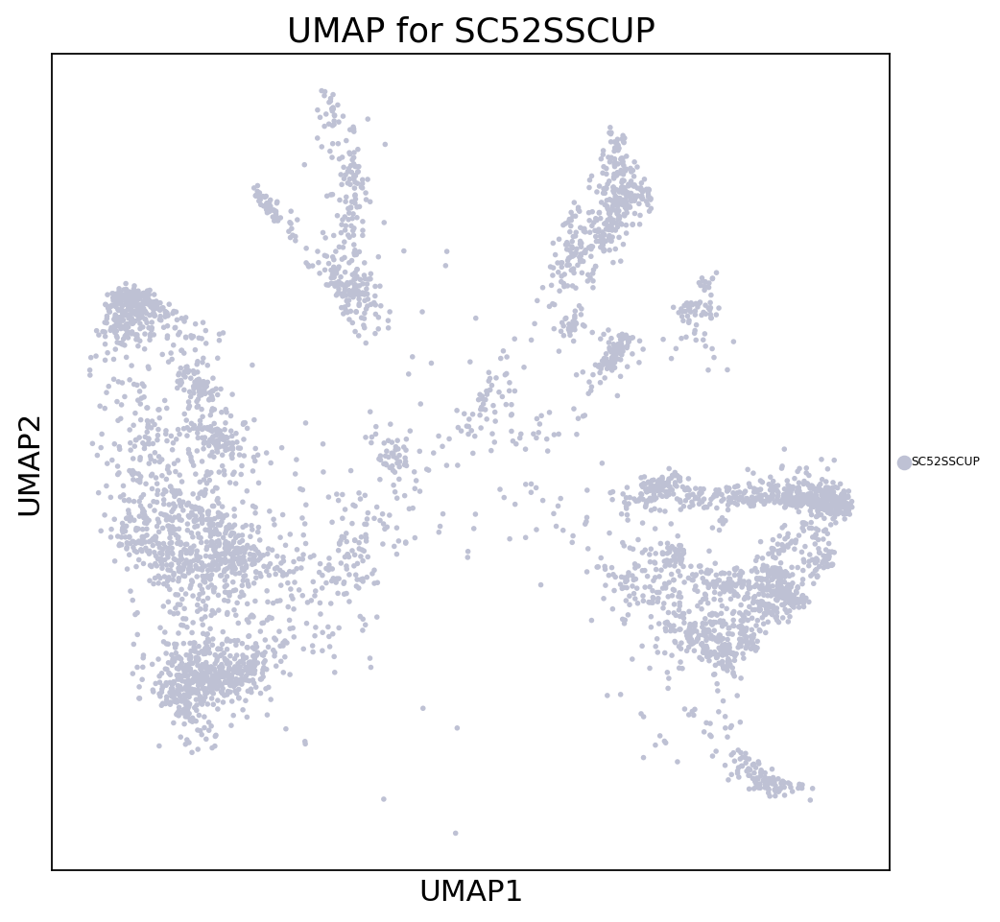

SC108SSCLOW


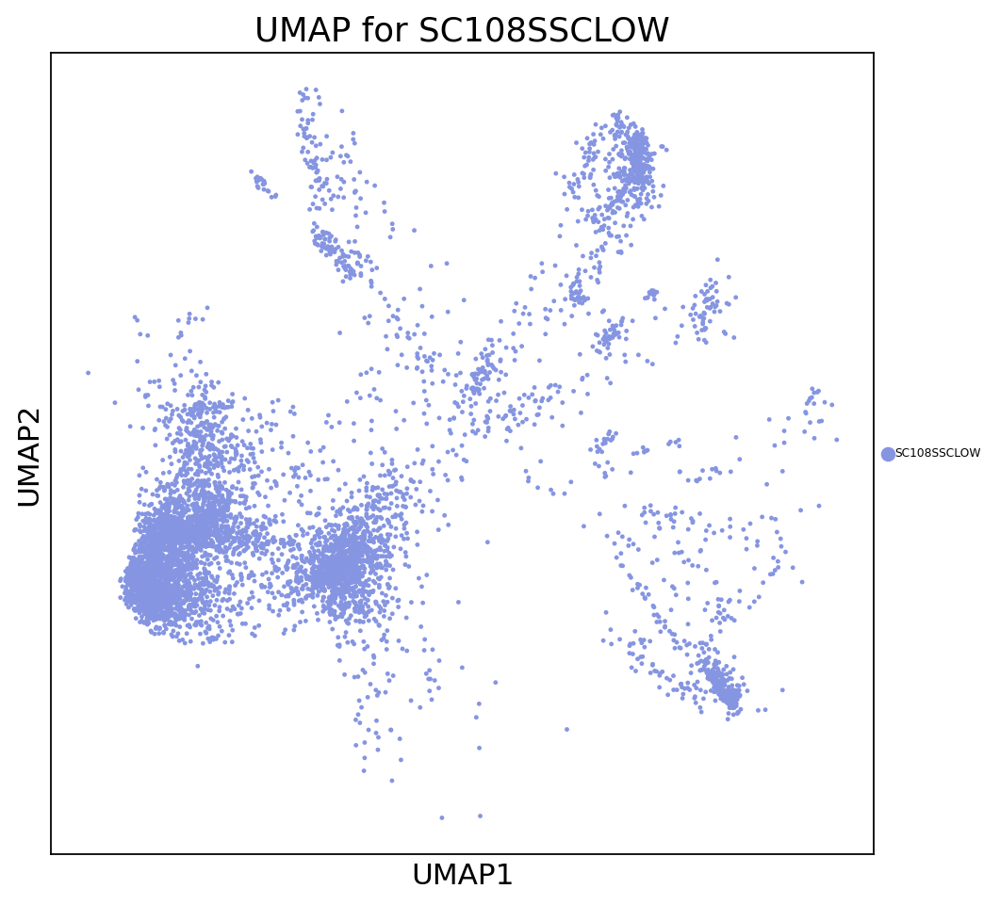

SC135SSCLOW


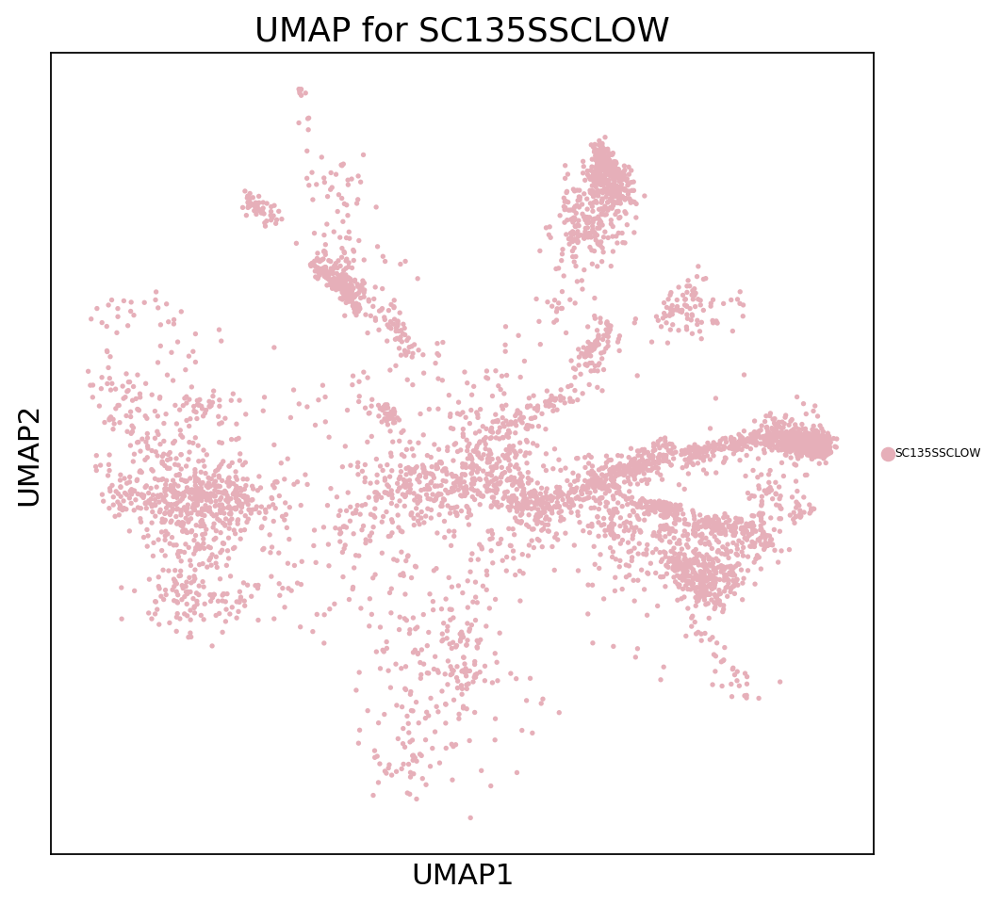

SC63SSCLOW


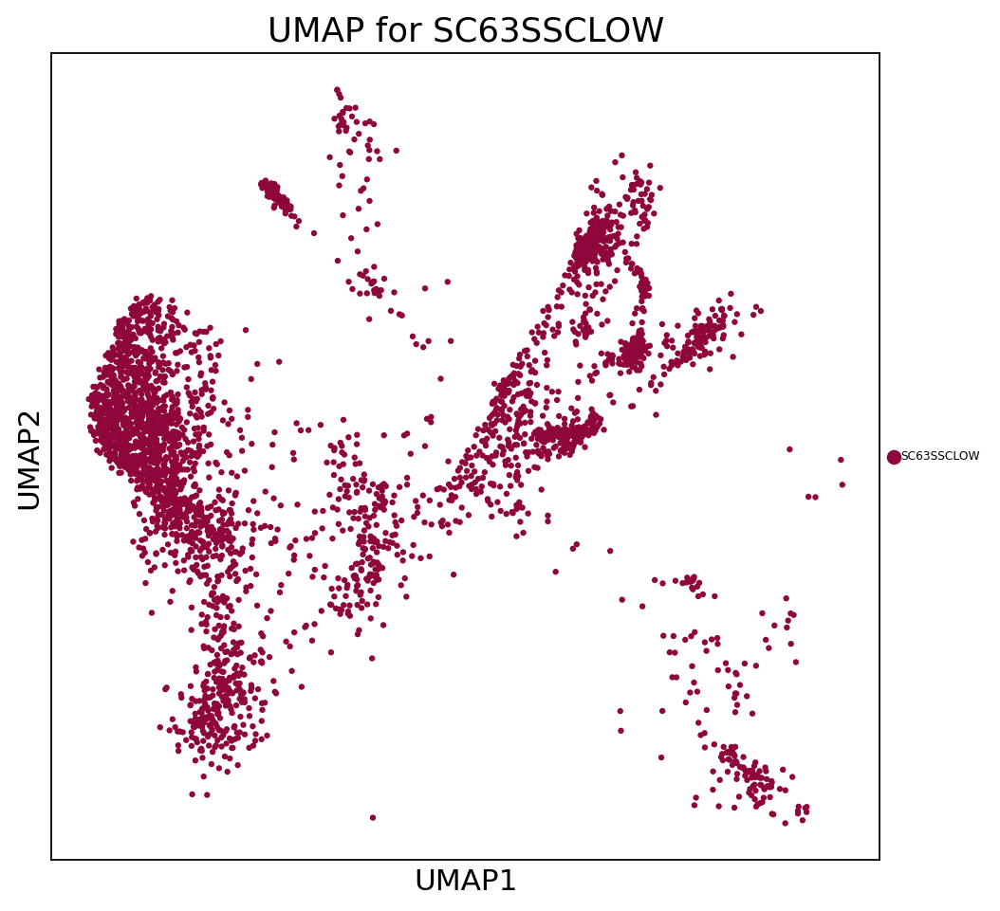

SC156NORUP


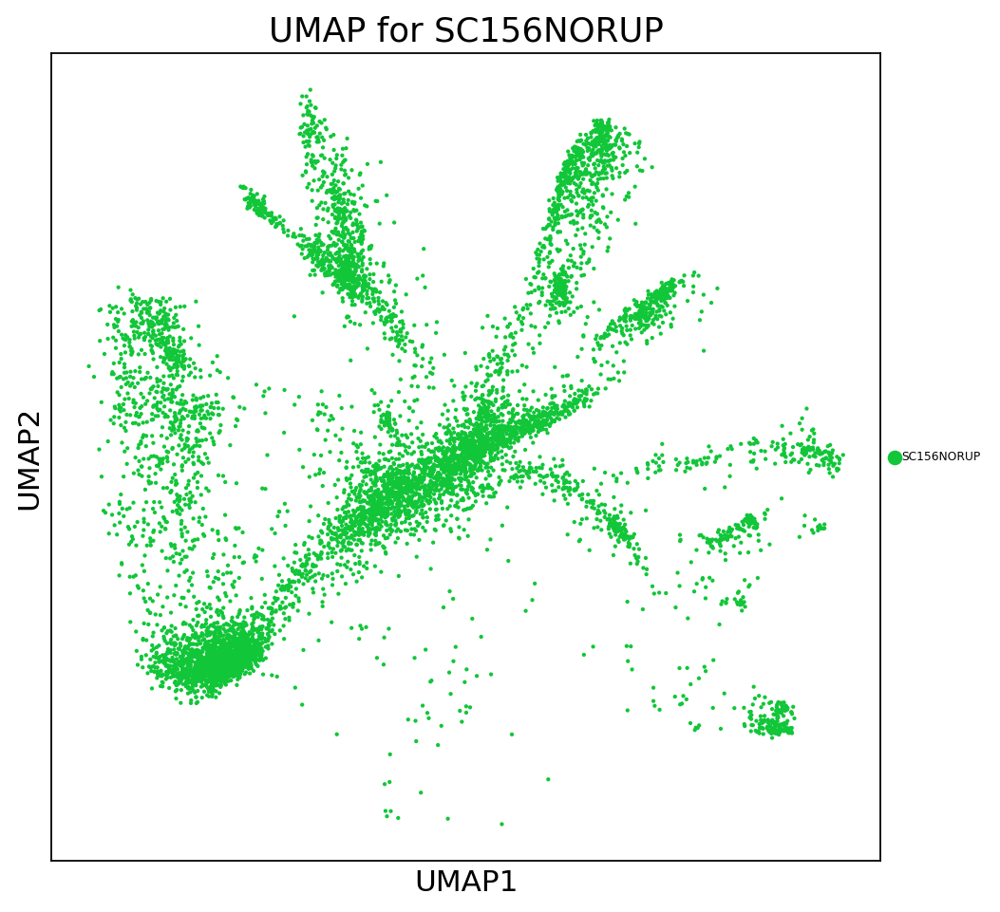

SC59NOR


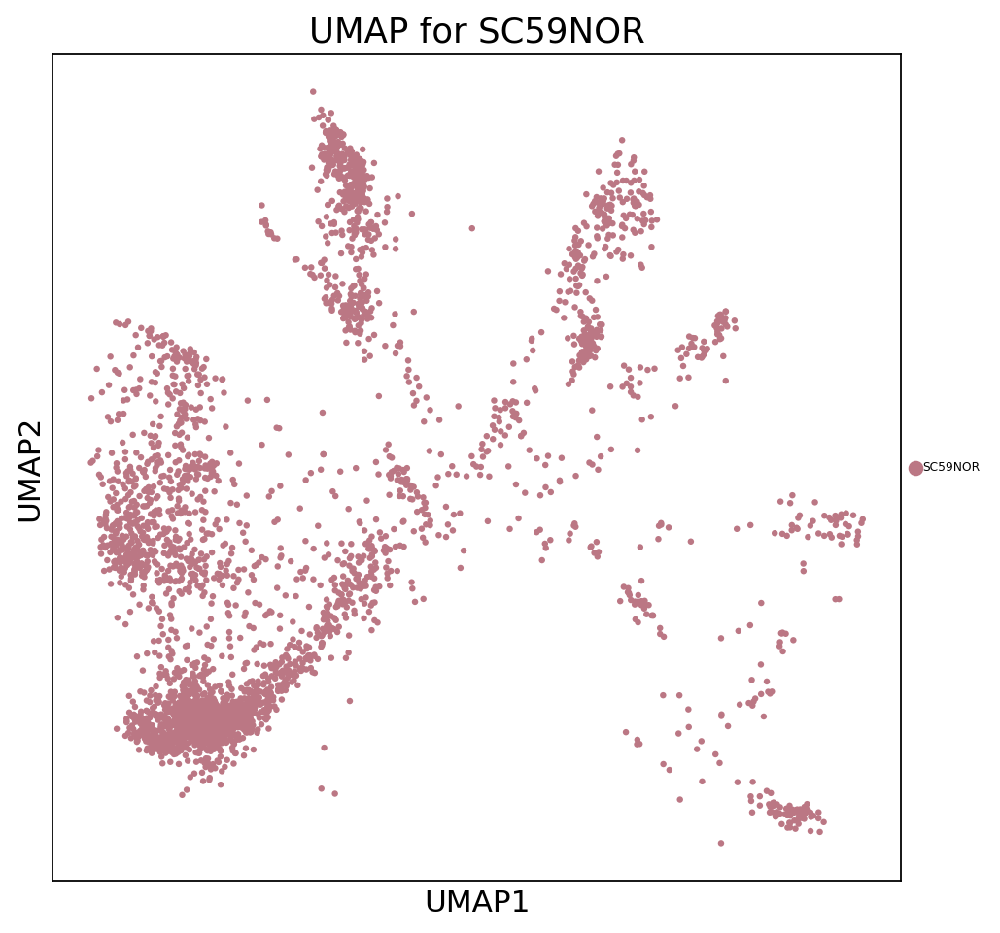

SC45NOR


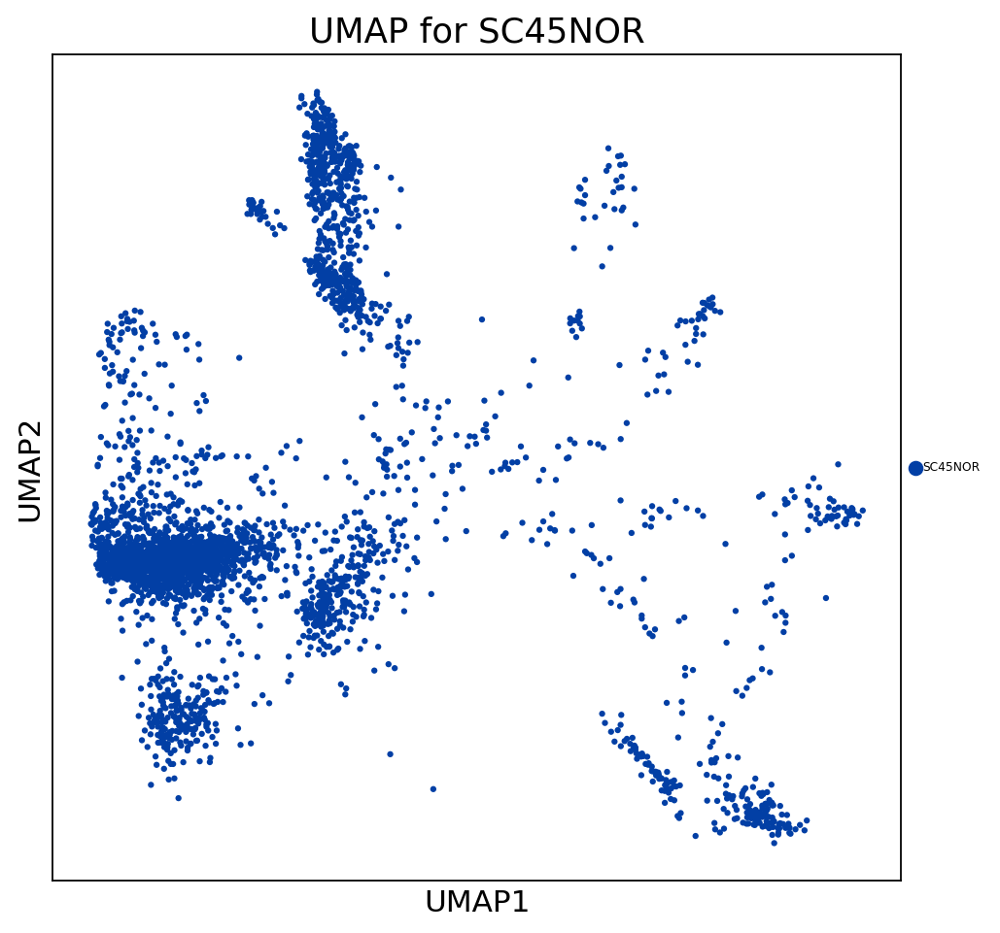

SC64SSCUP


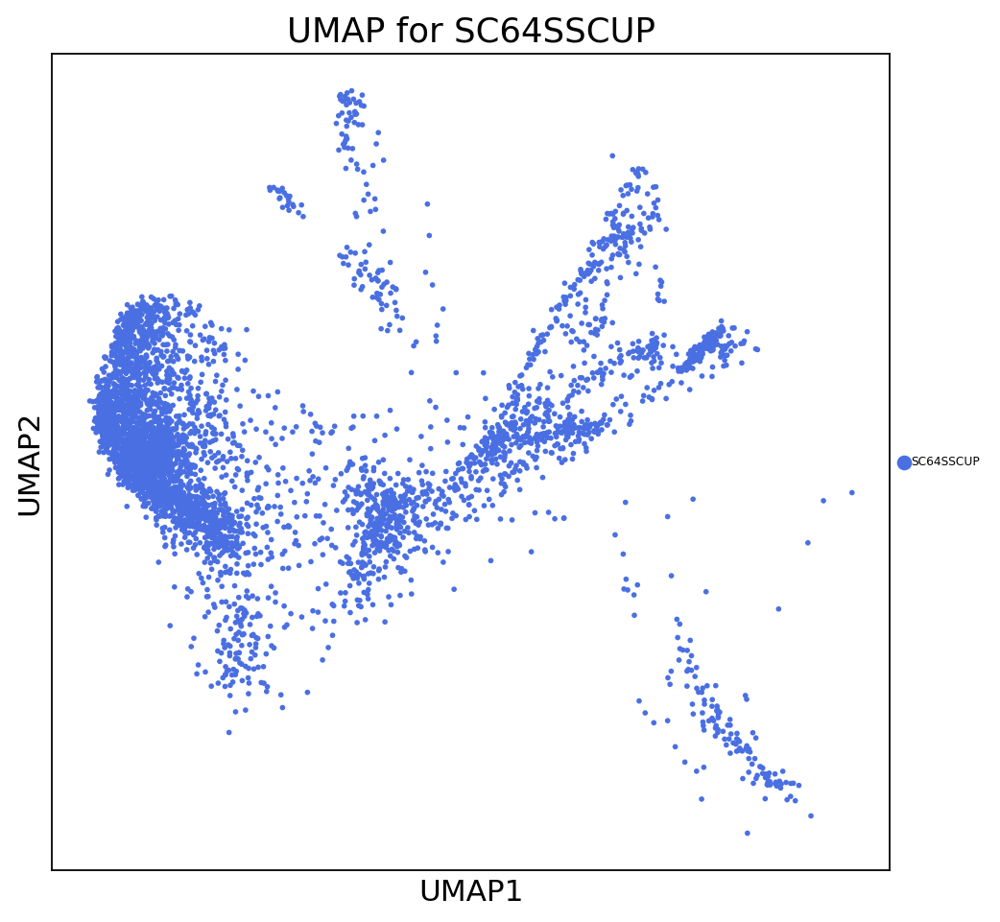

SC56NOR


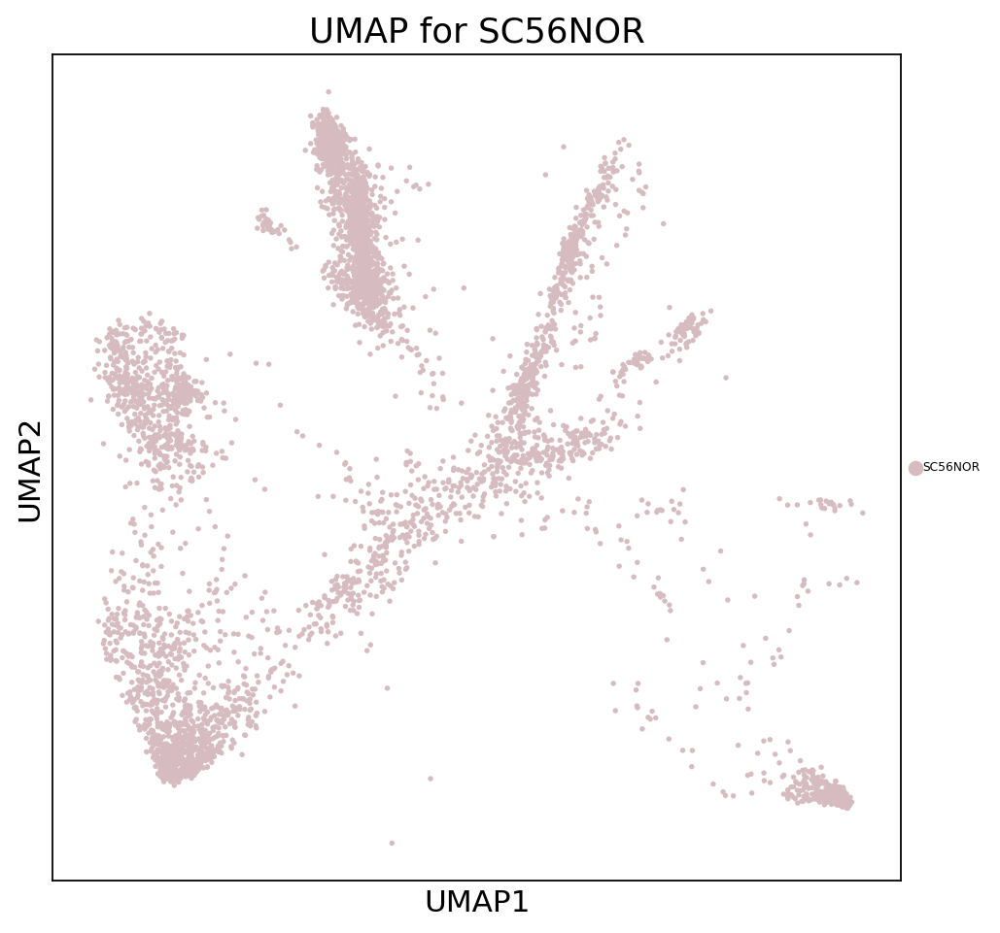

SC136SSCUP


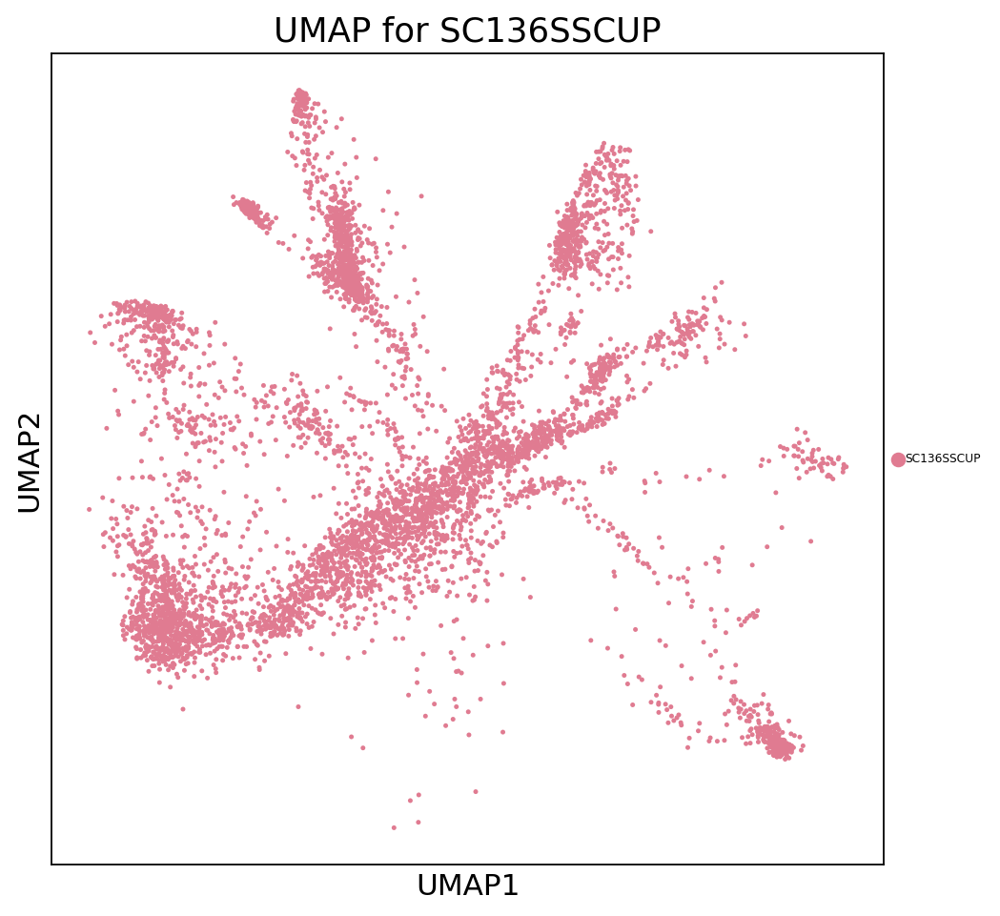

SC335


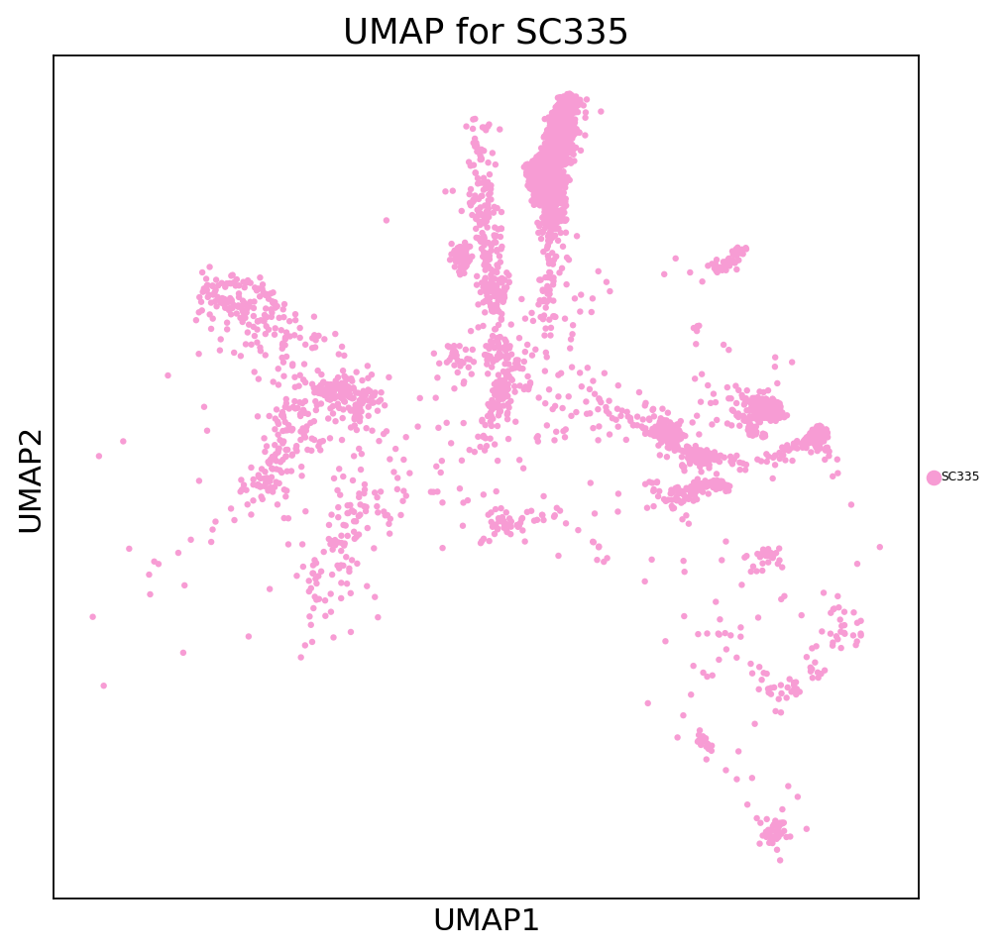

SC315


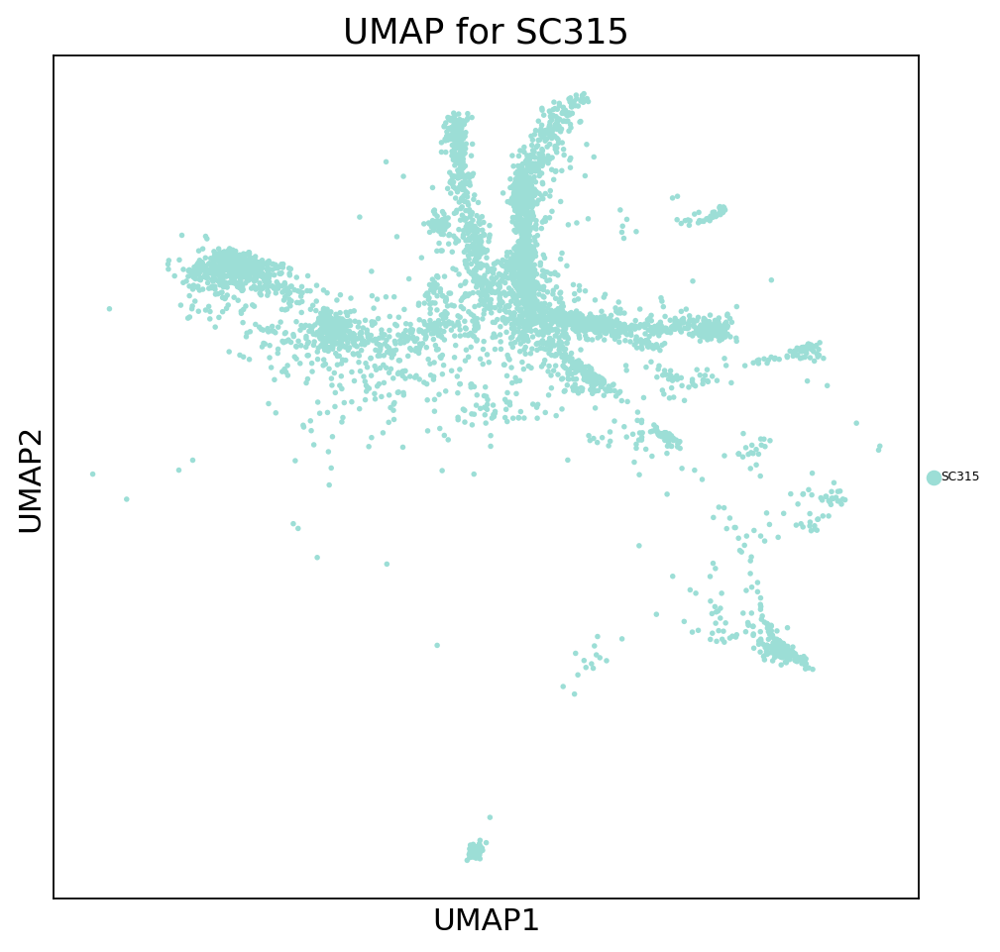

SC323


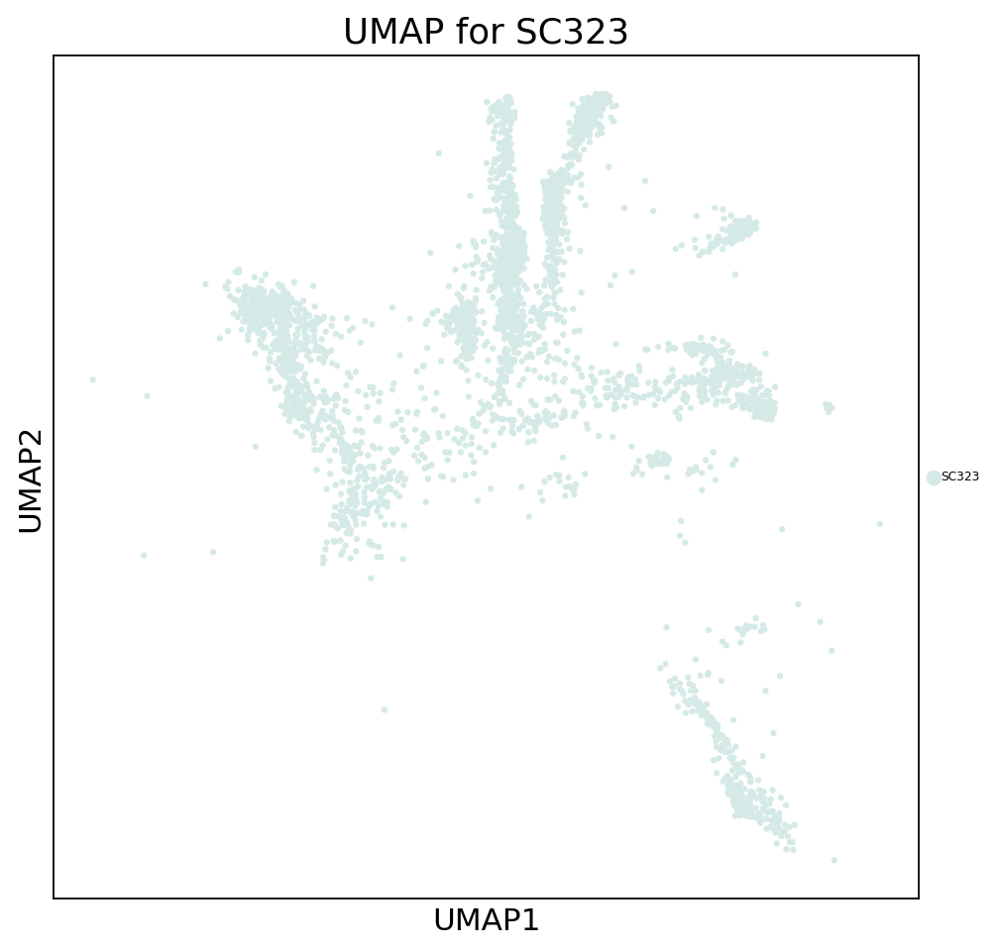

SC293


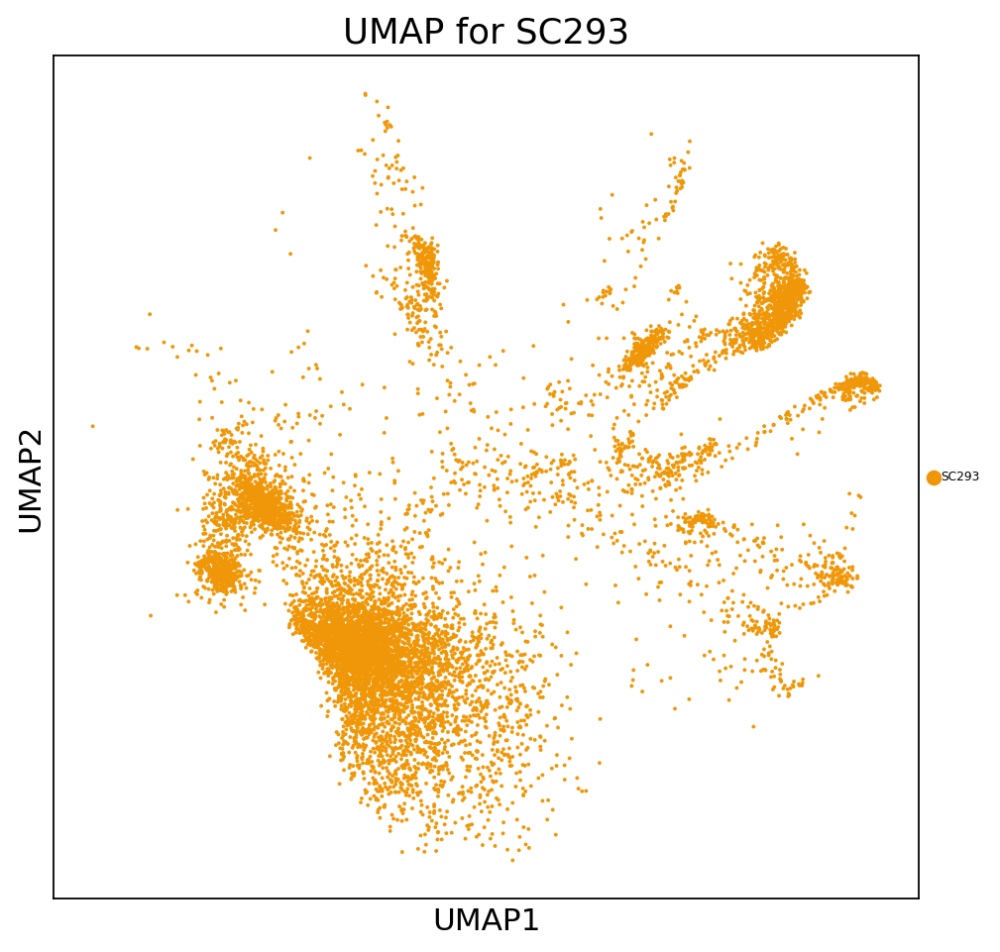

SC334


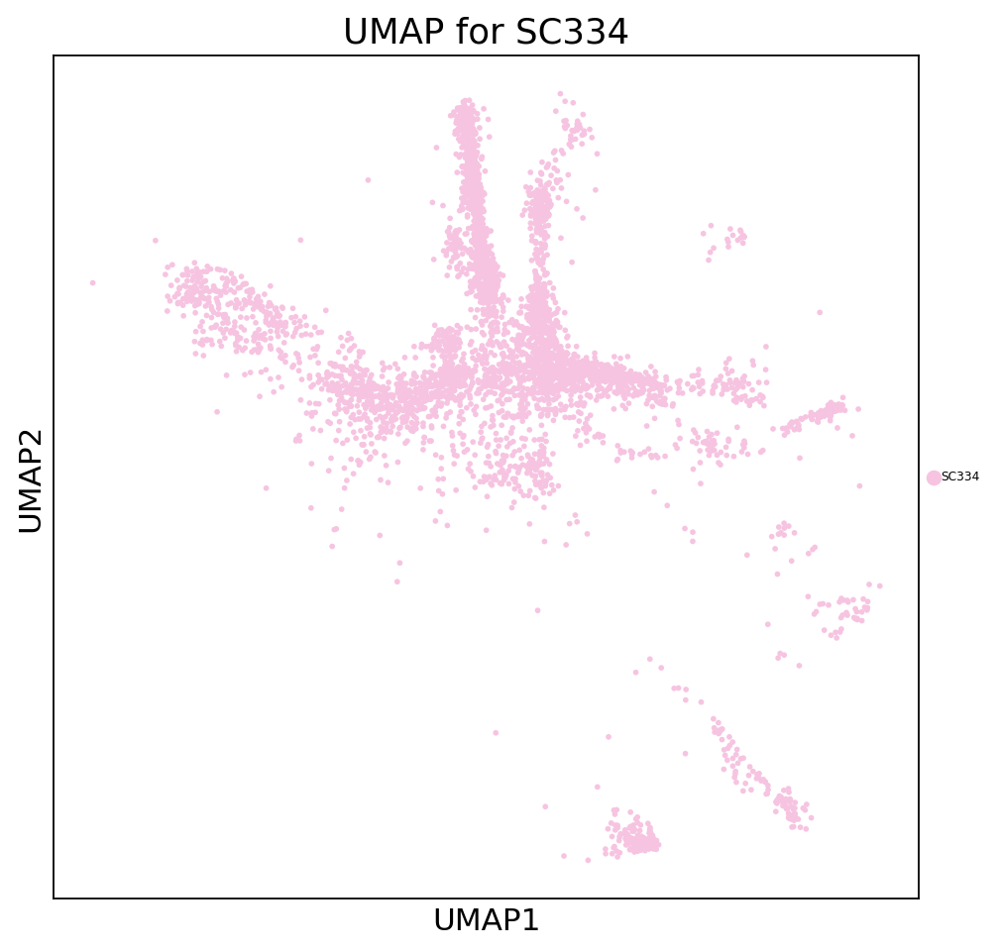

SC284


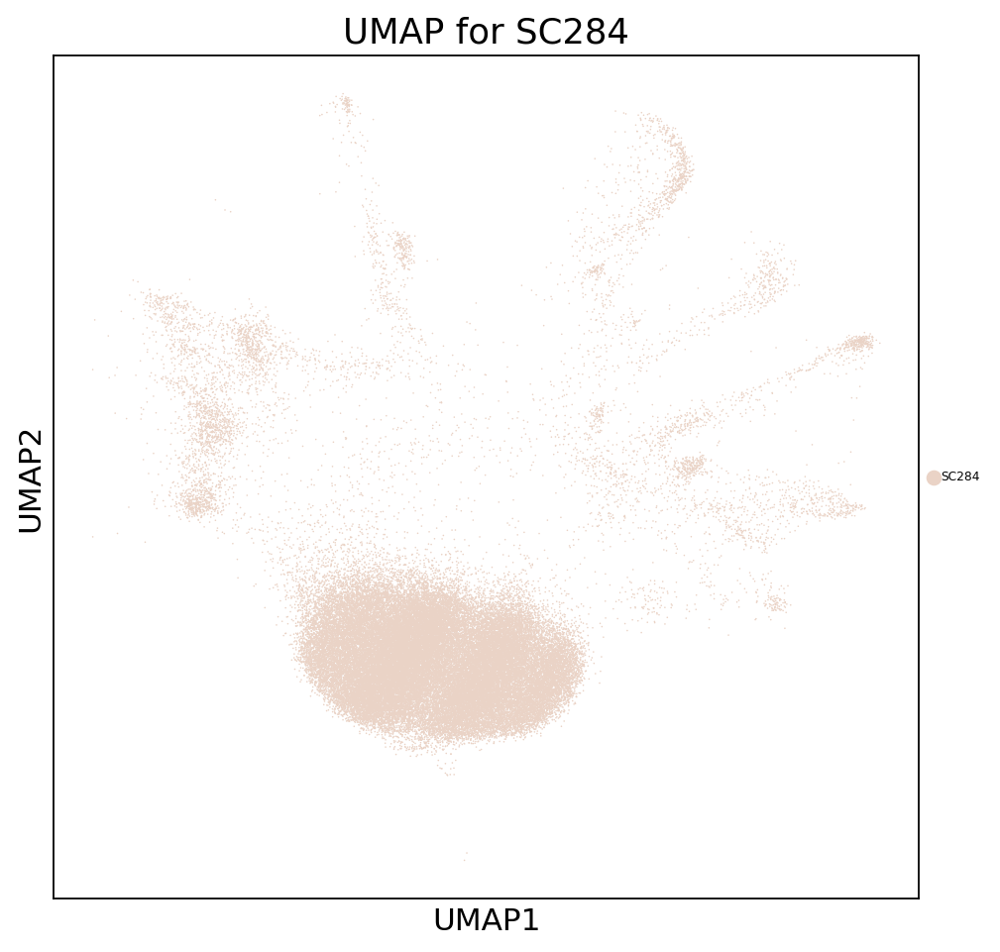

SC277


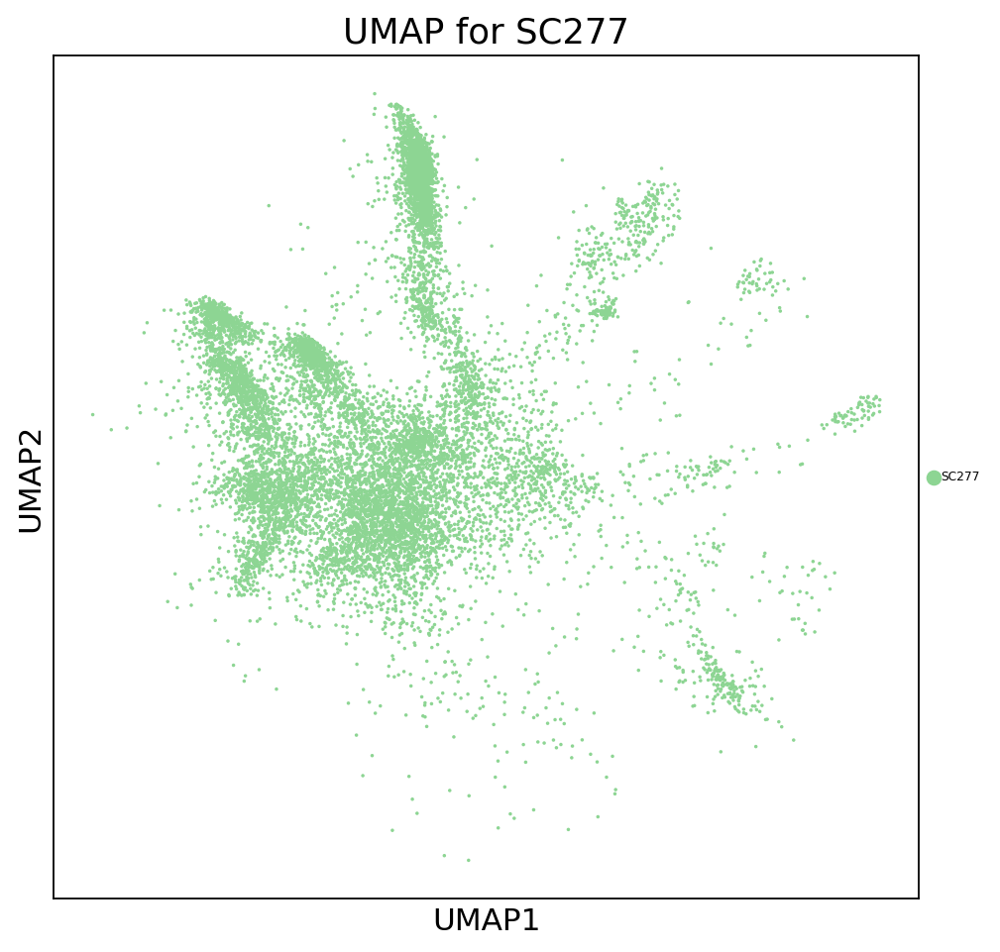

SC286


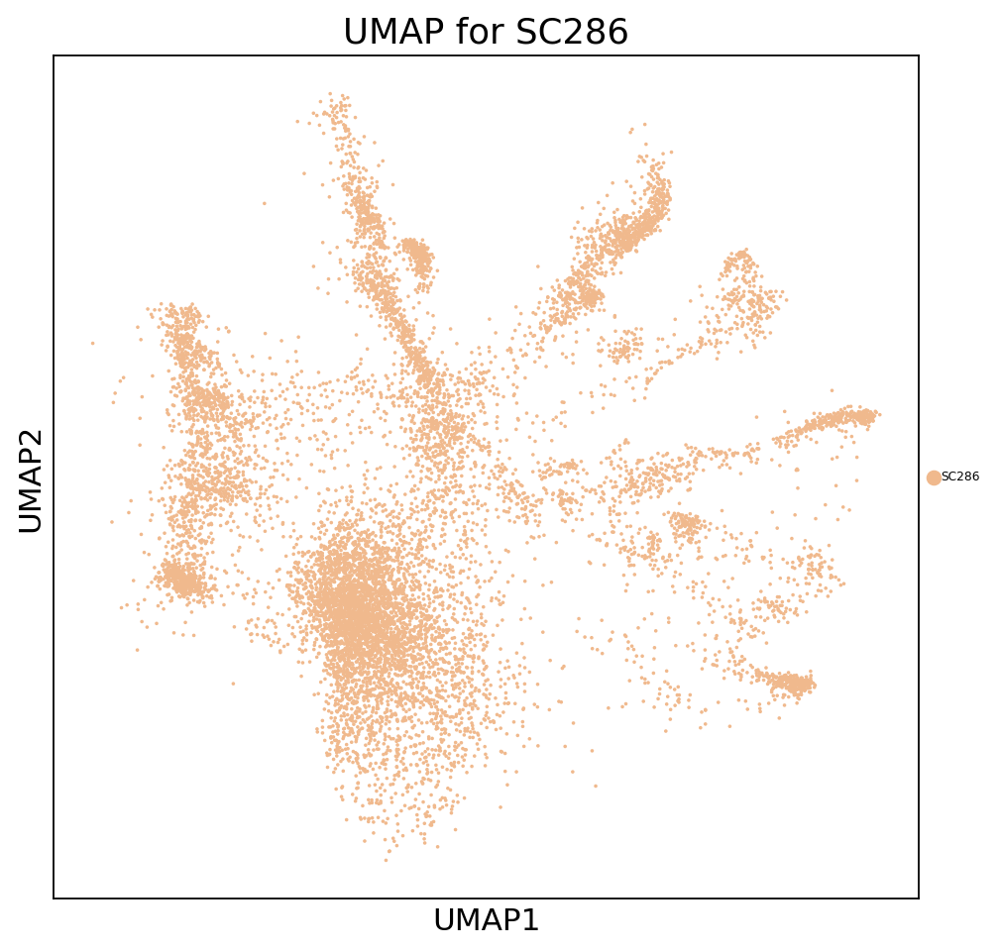

SC281


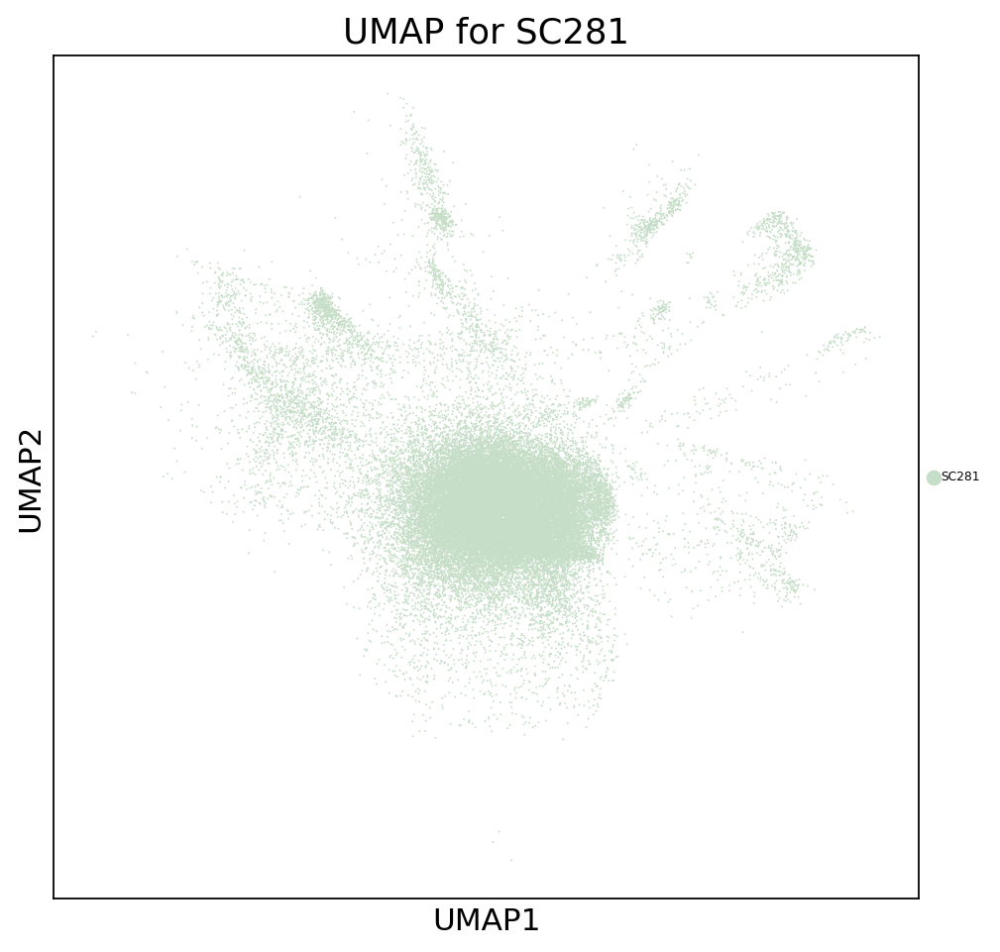

SC333


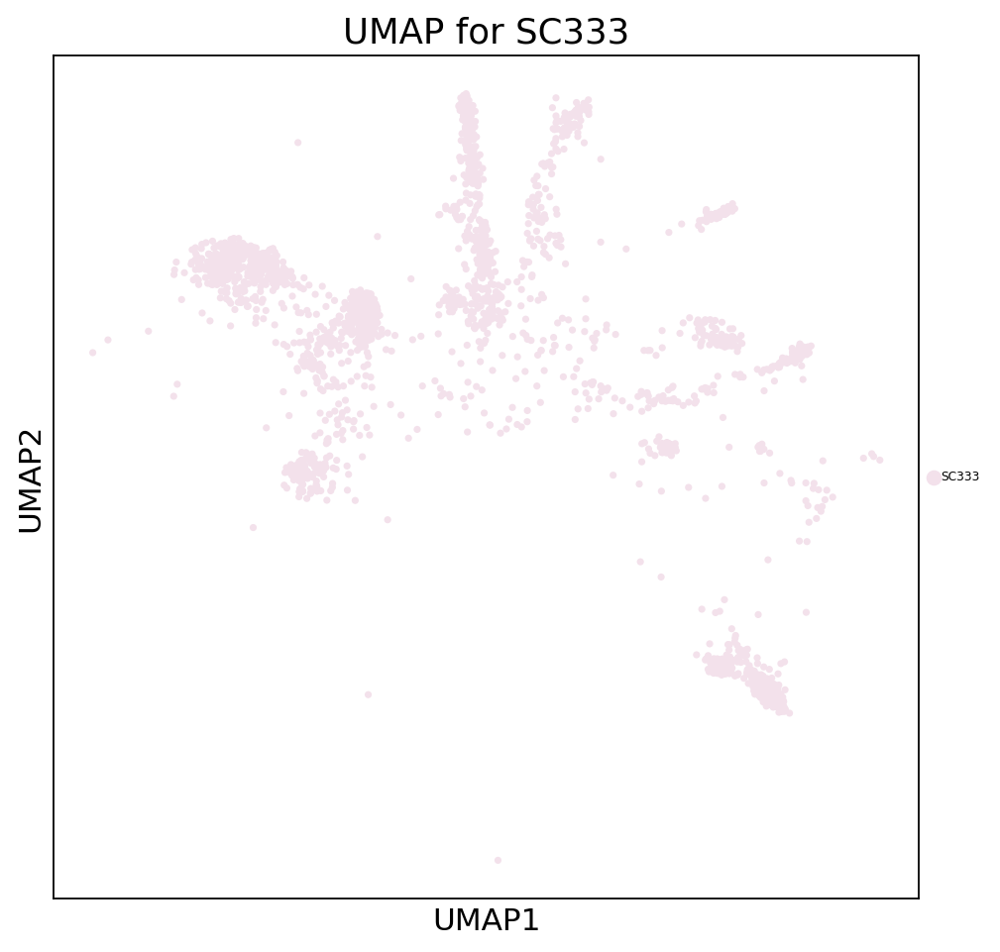

SC313


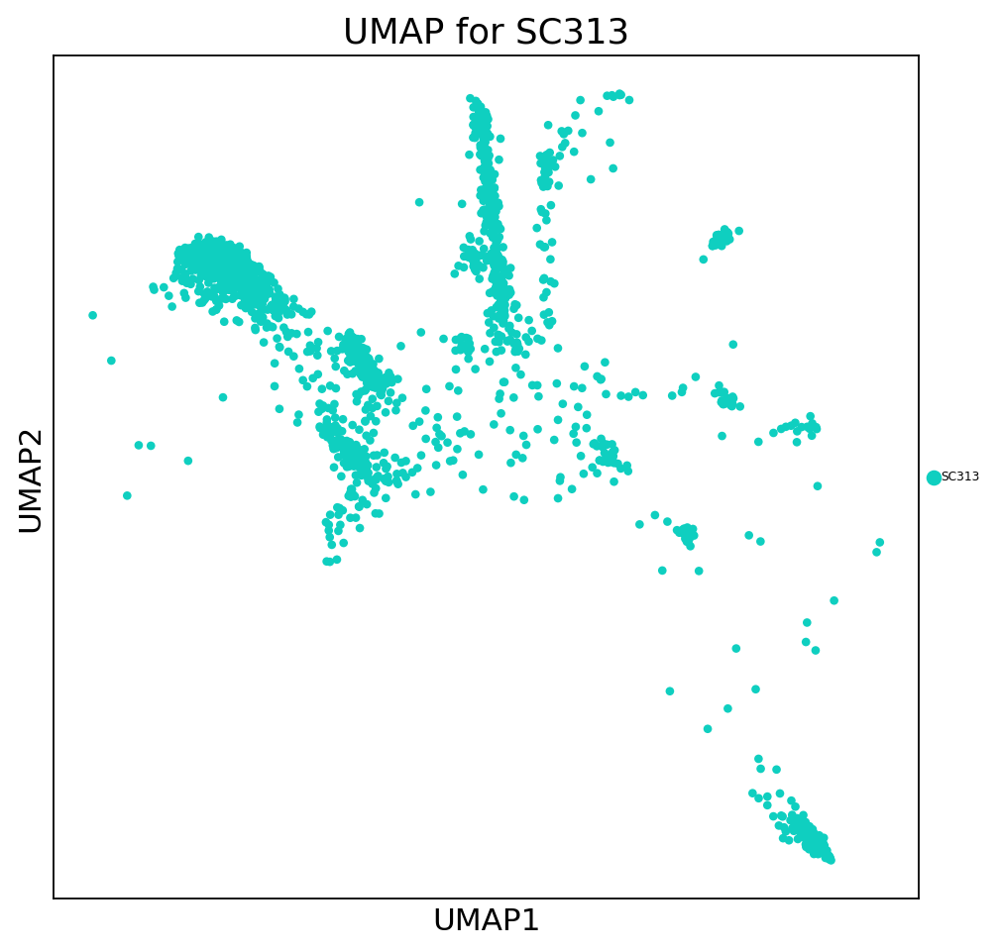

In [82]:
# Loop over each unique batch and generate a UMAP plot
for batch in adata3.obs['sample'].unique():
    print(batch)
    # Create a new adata object for the specific batch
    adata_batch = adata3[adata3.obs['sample'] == batch]
    
    # Plot UMAP for this batch
    sc.pl.umap(adata_batch, color='sample', title=f"UMAP for {batch}")

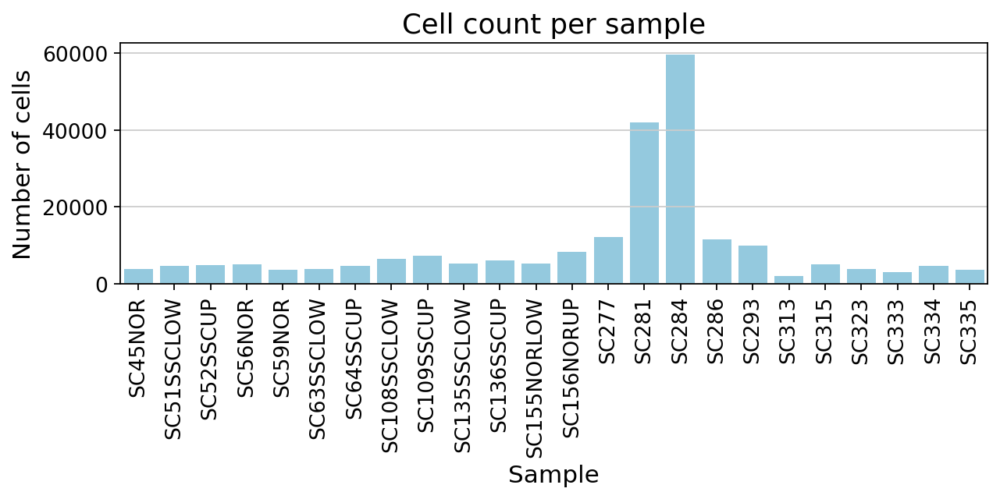

In [83]:
#Check and removal samples with less than 200 cells
import matplotlib.pyplot as plt
import seaborn as sns

# Count number of cells per sample
cell_counts = adata3.obs['sample'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,4))
sns.barplot(x=cell_counts.index, y=cell_counts.values, color="skyblue")
plt.xticks(rotation=90)
plt.ylabel("Number of cells")
plt.xlabel("Sample")
plt.title("Cell count per sample")
plt.tight_layout()
plt.show()


In [63]:
# Define minimum cell count threshold
#min_cells = 500

# Identify samples that meet the threshold
#valid_samples = cell_counts[cell_counts >= min_cells].index

# Filter the AnnData object
#adata3 = adata3[adata3.obs['sample'].isin(valid_samples)].copy()

#print(f"Kept {len(valid_samples)} samples with ≥ {min_cells} cells.")
#print(f"Remaining cells: {adata3.n_obs}")


# Annotation

In [84]:
import celltypist
import scanpy as sc
from celltypist import models

# Download the latest immune cell model
model = celltypist.models.Model.load('/home/ciperi/data/Atlas_SSC/Celltypist_model/Human_Lung_Atlas.pkl')

adata = sc.AnnData(adata3.raw.X.copy(), var=adata3.raw.var.copy(), obs=adata3.obs.copy())
print(adata.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 231814969 stored elements and shape (224516, 18738)>
  Coords	Values
  (0, 18725)	8.0
  (0, 18722)	8.0
  (0, 18720)	4.0
  (0, 18719)	23.0
  (0, 18718)	15.0
  (0, 18716)	3.0
  (0, 18715)	13.0
  (0, 18714)	7.0
  (0, 18713)	6.0
  (0, 18695)	1.0
  (0, 18361)	2.0
  (0, 18180)	1.0
  (0, 18170)	1.0
  (0, 18089)	1.0
  (0, 17916)	1.0
  (0, 17850)	1.0
  (0, 17761)	1.0
  (0, 17705)	5.0
  (0, 17620)	1.0
  (0, 17588)	1.0
  (0, 17518)	2.0
  (0, 17074)	1.0
  (0, 17064)	1.0
  (0, 16950)	2.0
  (0, 16533)	1.0
  :	:
  (224515, 8352)	3.0
  (224515, 8353)	3.0
  (224515, 8355)	1.0
  (224515, 8358)	1.0
  (224515, 8359)	2.0
  (224515, 8360)	3.0
  (224515, 8369)	3.0
  (224515, 8372)	1.0
  (224515, 8373)	1.0
  (224515, 18019)	6.0
  (224515, 18020)	2.0
  (224515, 18026)	2.0
  (224515, 18713)	44.0
  (224515, 18714)	21.0
  (224515, 18715)	86.0
  (224515, 18716)	64.0
  (224515, 18717)	3.0
  (224515, 18718)	109.0
  (224515, 18719)	47.0
  (224515, 18720)	4

In [85]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [86]:
import numpy as np

# Quick check
X = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X

print(f"Min:  {X.min():.2f}")
print(f"Max:  {X.max():.2f}")
print(f"Mean: {X.mean():.2f}")
print(f"Std:  {X.std():.2f}")

Min:  0.00
Max:  9.11
Mean: 0.08
Std:  0.43


🔬 Input data has 224516 cells and 18738 genes
🔗 Matching reference genes in the model
🧬 4716 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


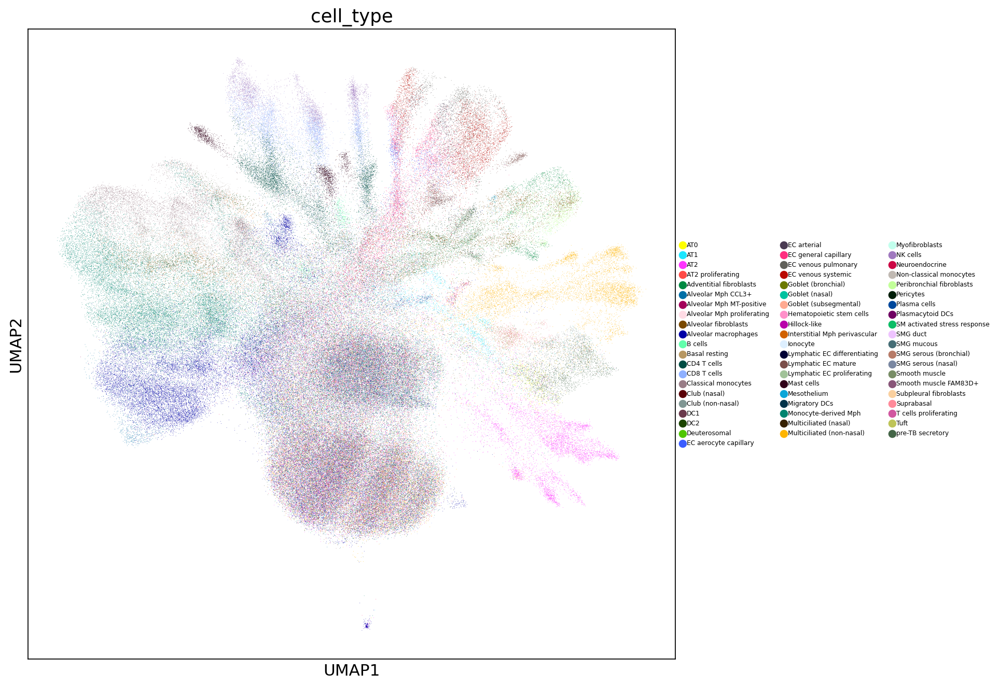

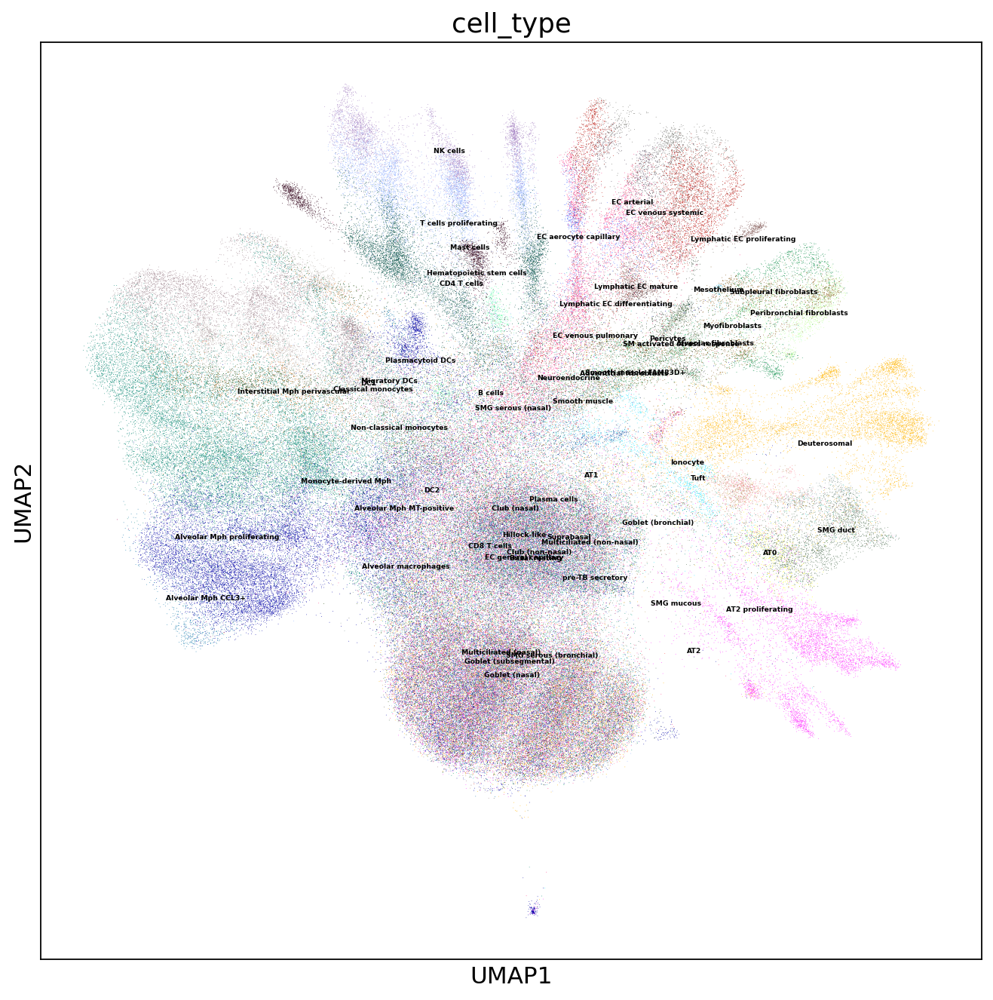

In [87]:
# Predict cell types
predictions = celltypist.annotate(adata, model=model)

# Store predictions in adata.obs
adata3.obs['cell_type'] = predictions.predicted_labels

plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type'])

sc.pl.umap(adata3, color=['cell_type'], legend_loc = "on data", legend_fontsize= 'x-small')

Keeping 50 cell types with ≥ 50 cells
Remaining cells: 224360
Remaining cell types: 50


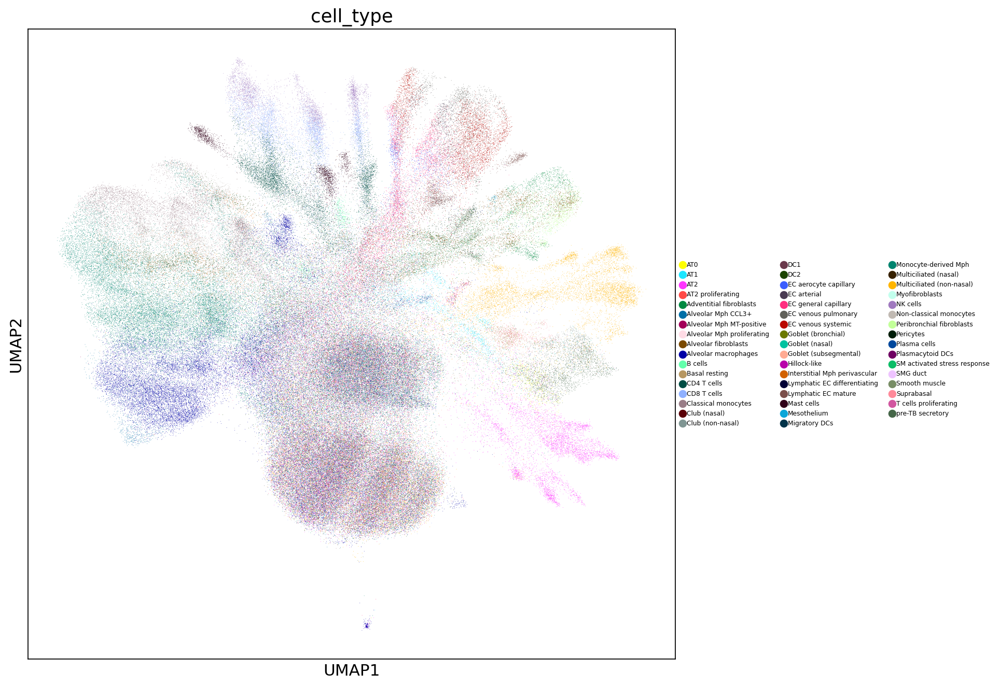

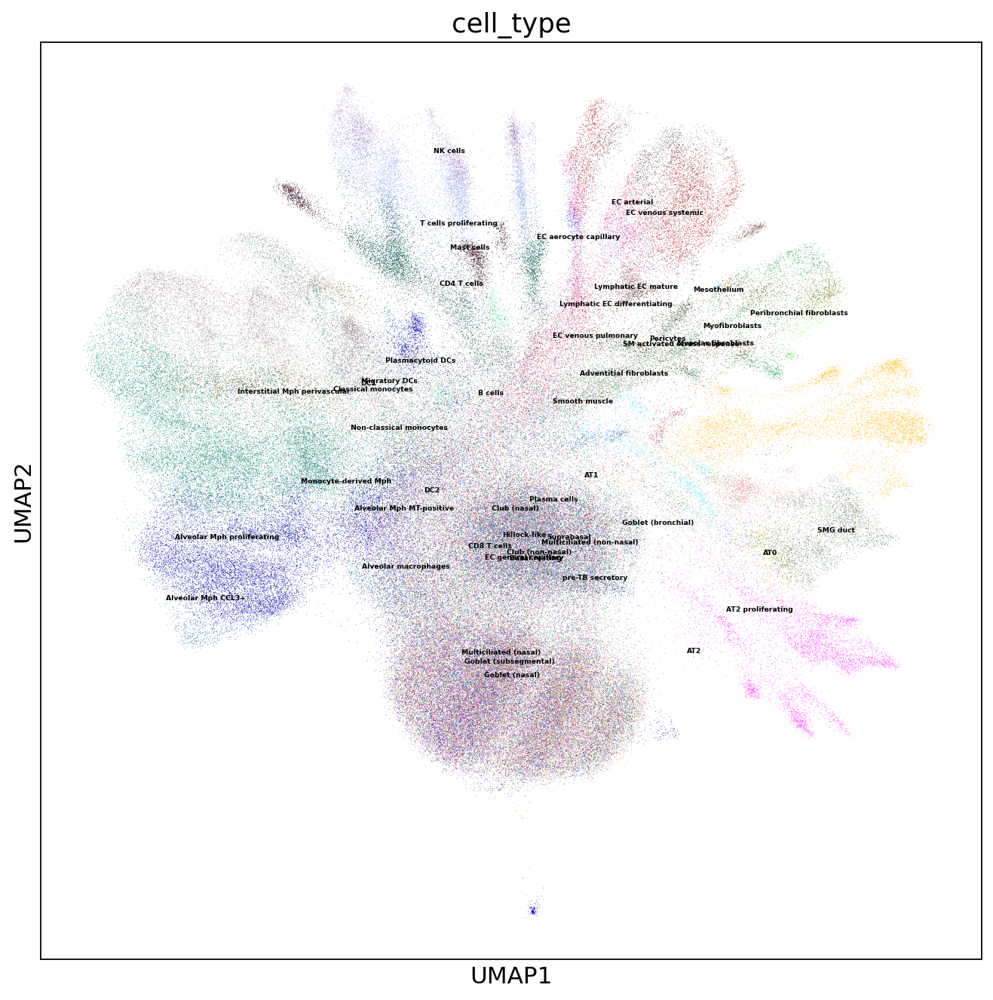

In [88]:
import pandas as pd

# Define the minimum cell count threshold
min_cells = 50

# Count cells per cell type
celltype_counts = adata3.obs['cell_type'].value_counts()

# Identify cell types that meet the threshold
valid_celltypes = celltype_counts[celltype_counts >= min_cells].index

print(f"Keeping {len(valid_celltypes)} cell types with ≥ {min_cells} cells")

# Filter AnnData to keep only valid cell types
adata3 = adata3[adata3.obs['cell_type'].isin(valid_celltypes)].copy()

# Report the result
print(f"Remaining cells: {adata3.n_obs}")
print(f"Remaining cell types: {adata3.obs['cell_type'].nunique()}")



plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type'])

sc.pl.umap(adata3, color=['cell_type'], legend_loc = "on data", legend_fontsize= 'x-small')




In [89]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "cell_type"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata3.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata3[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata3.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


AT0                  → kept 469 / 469 cells
AT1                  → kept 500 / 2475 cells
AT2                  → kept 500 / 9792 cells
AT2 proliferating    → kept 121 / 121 cells
Adventitial fibroblasts → kept 500 / 4062 cells
Alveolar Mph CCL3+   → kept 500 / 1102 cells
Alveolar Mph MT-positive → kept 80 / 80 cells
Alveolar Mph proliferating → kept 500 / 632 cells
Alveolar fibroblasts → kept 500 / 2805 cells
Alveolar macrophages → kept 500 / 30574 cells
B cells              → kept 500 / 1211 cells
Basal resting        → kept 500 / 5293 cells
CD4 T cells          → kept 500 / 8758 cells
CD8 T cells          → kept 500 / 17692 cells
Classical monocytes  → kept 500 / 13903 cells
Club (nasal)         → kept 500 / 649 cells
Club (non-nasal)     → kept 500 / 1026 cells
DC1                  → kept 75 / 75 cells
DC2                  → kept 500 / 5446 cells
EC aerocyte capillary → kept 500 / 1021 cells
EC arterial          → kept 500 / 1558 cells
EC general capillary → kept 500 / 24051 cells
EC

In [90]:
sc.tl.rank_genes_groups(adata_sub, groupby='cell_type', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

🔬 Input data has 224516 cells and 18738 genes
🔗 Matching reference genes in the model
🧬 3666 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


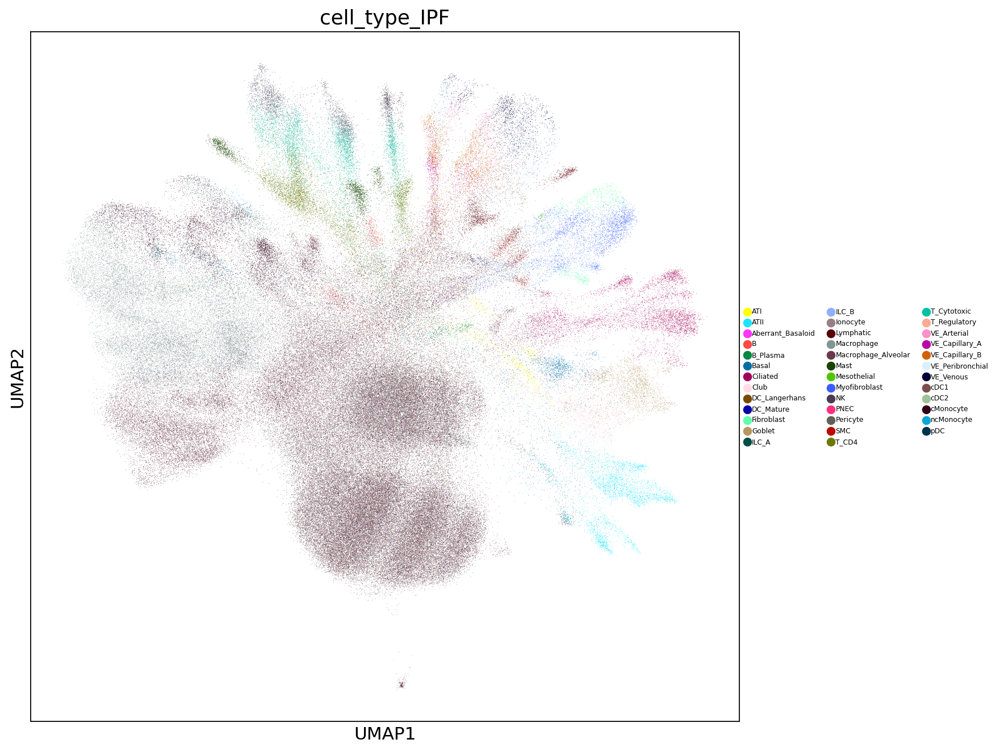

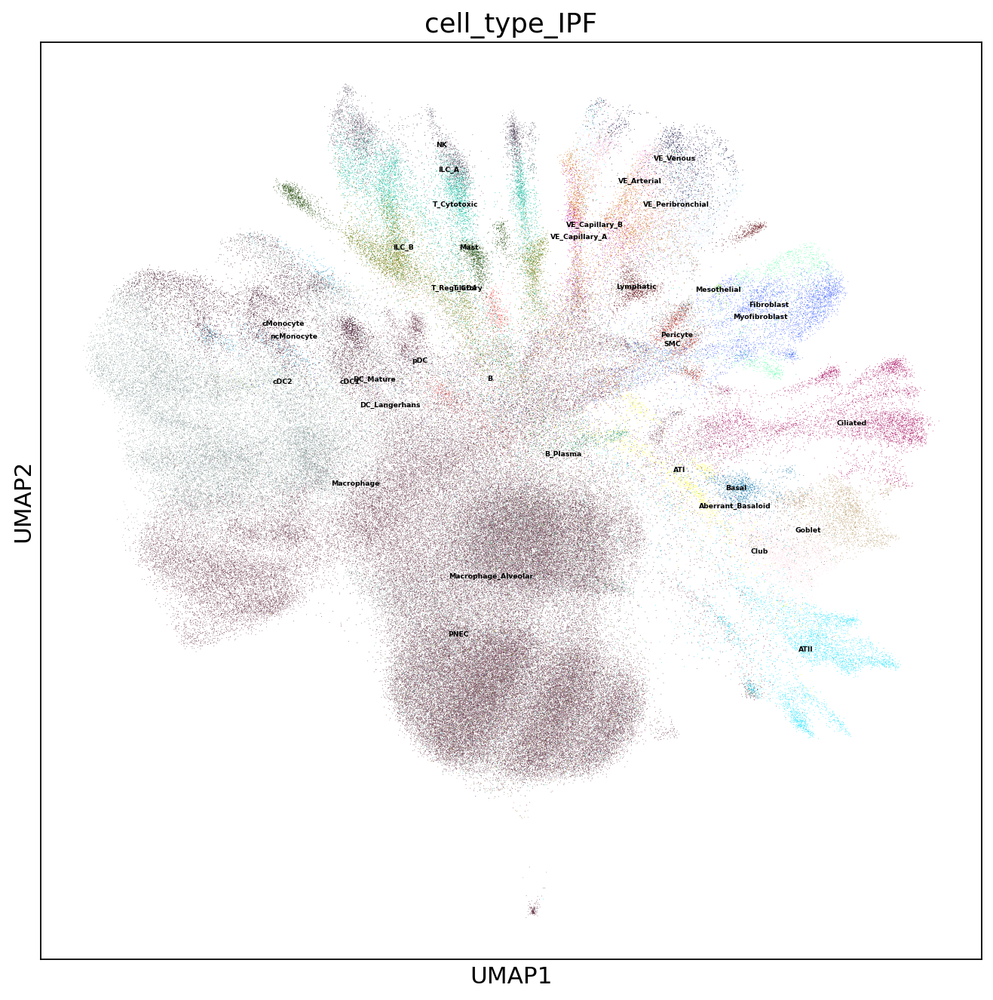

In [91]:
# Download the latest immune cell model
model = celltypist.models.Model.load('/home/ciperi/data/Atlas_SSC/Celltypist_model/Human_IPF_Lung.pkl')


predictions = celltypist.annotate(adata, model=model)

# Store predictions in adata.obs
adata3.obs['cell_type_IPF'] = predictions.predicted_labels

plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type_IPF'])

sc.pl.umap(adata3, color=['cell_type_IPF'], legend_loc = "on data", legend_fontsize= 'x-small')

Keeping 34 cell types with ≥ 50 cells
Remaining cells: 224296
Remaining cell types: 50


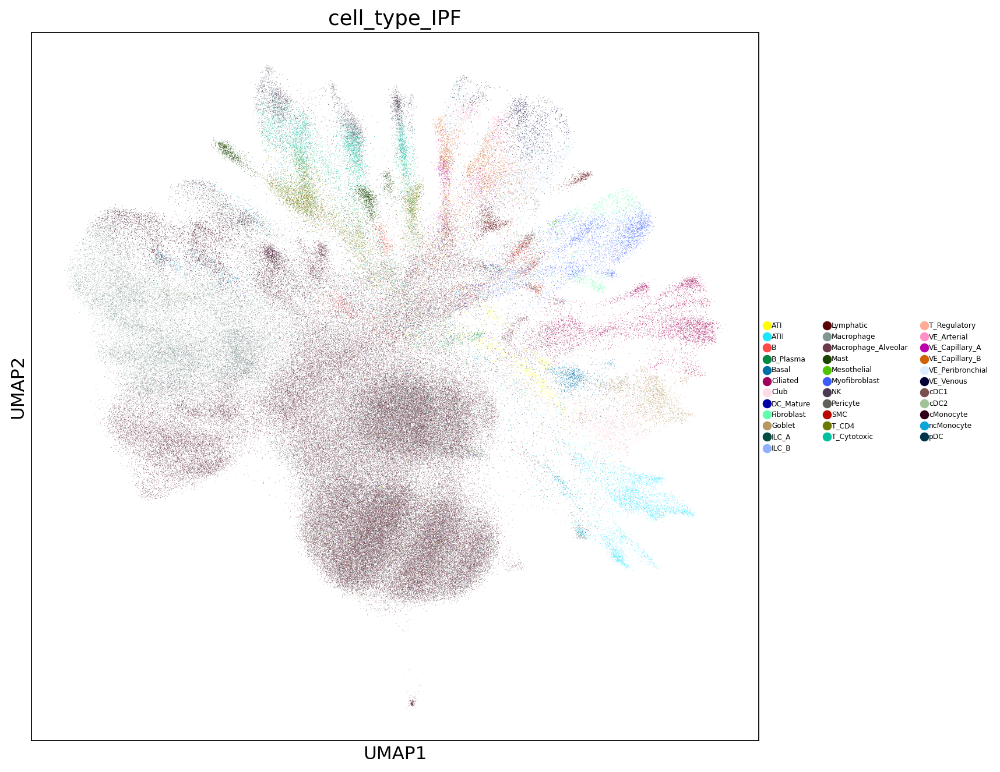

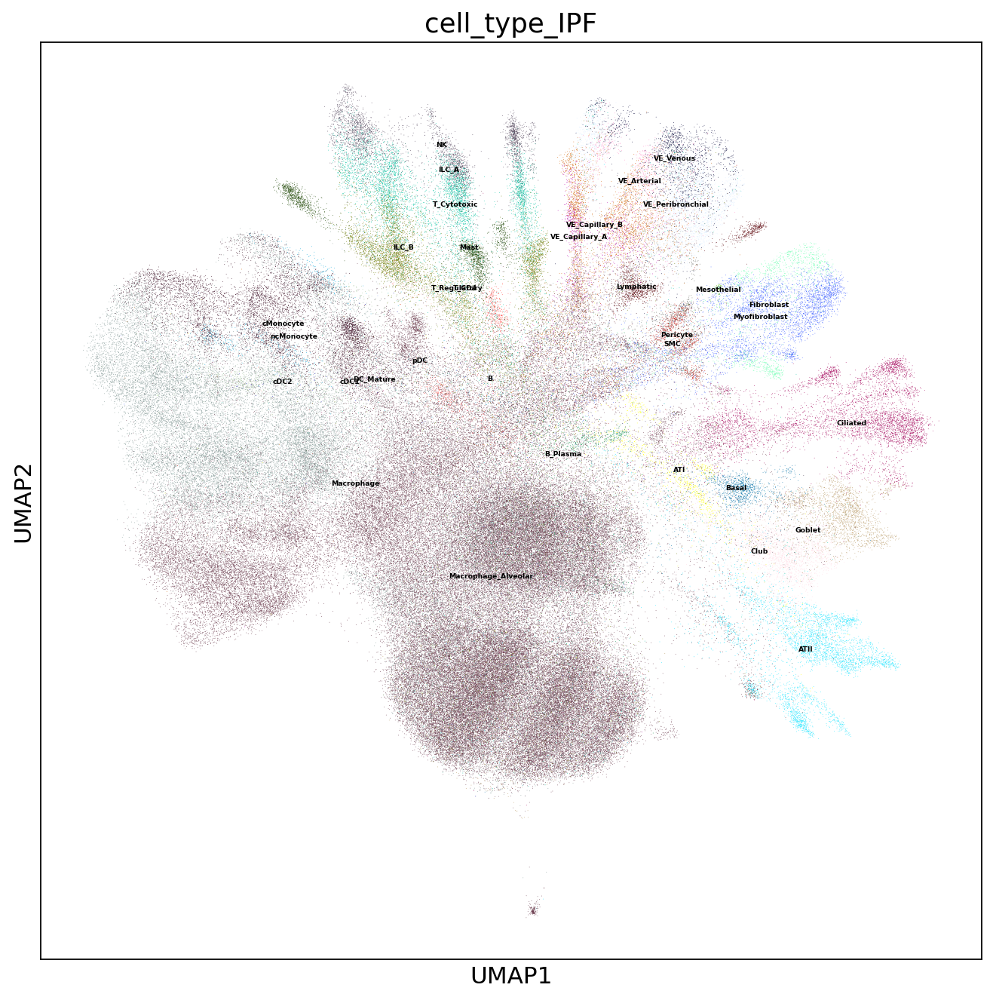

In [92]:
import pandas as pd

# Define the minimum cell count threshold
min_cells = 50

# Count cells per cell type
celltype_counts = adata3.obs['cell_type_IPF'].value_counts()

# Identify cell types that meet the threshold
valid_celltypes = celltype_counts[celltype_counts >= min_cells].index

print(f"Keeping {len(valid_celltypes)} cell types with ≥ {min_cells} cells")

# Filter AnnData to keep only valid cell types
adata3 = adata3[adata3.obs['cell_type_IPF'].isin(valid_celltypes)].copy()

# Report the result
print(f"Remaining cells: {adata3.n_obs}")
print(f"Remaining cell types: {adata3.obs['cell_type'].nunique()}")



plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type_IPF'])

sc.pl.umap(adata3, color=['cell_type_IPF'], legend_loc = "on data", legend_fontsize= 'x-small')




In [93]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "cell_type_IPF"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata3.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata3[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata3.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


ATI                  → kept 500 / 1043 cells
ATII                 → kept 500 / 4425 cells
B                    → kept 500 / 906 cells
B_Plasma             → kept 500 / 1192 cells
Basal                → kept 500 / 1362 cells
Ciliated             → kept 500 / 5689 cells
Club                 → kept 500 / 3144 cells
DC_Mature            → kept 98 / 98 cells
Fibroblast           → kept 500 / 1524 cells
Goblet               → kept 500 / 3361 cells
ILC_A                → kept 188 / 188 cells
ILC_B                → kept 92 / 92 cells
Lymphatic            → kept 500 / 1354 cells
Macrophage           → kept 500 / 42236 cells
Macrophage_Alveolar  → kept 500 / 111566 cells
Mast                 → kept 500 / 2268 cells
Mesothelial          → kept 63 / 63 cells
Myofibroblast        → kept 500 / 4292 cells
NK                   → kept 500 / 3346 cells
Pericyte             → kept 500 / 1034 cells
SMC                  → kept 500 / 1093 cells
T_CD4                → kept 500 / 8009 cells
T_Cytotoxic       

In [94]:
sc.tl.rank_genes_groups(adata_sub, groupby='cell_type_IPF', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

In [95]:
sc.tl.leiden(
    adata3,
    resolution=2,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="leiden_r2" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

['0', '10', '5', '22', '19', ..., '41', '38', '42', '43', '39']
Length: 44
Categories (44, object): ['0', '1', '2', '3', ..., '40', '41', '42', '43']


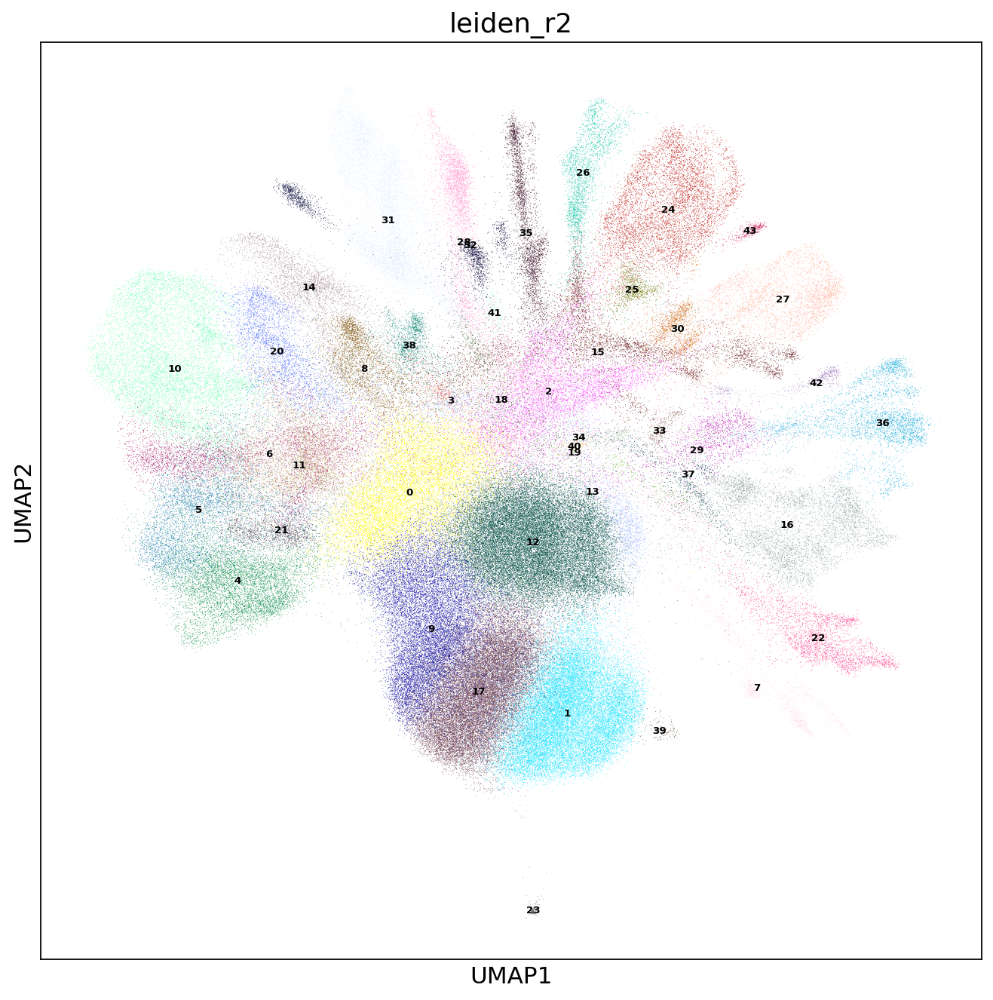

In [96]:
print(adata3.obs['leiden_r2'].unique())
sc.pl.umap(adata3, color='leiden_r2', legend_loc='on data')

In [97]:
sc.tl.leiden(
    adata3,
    resolution=0.4,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="leiden_r0.4" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

['0', '6', '4', '8', '1', ..., '9', '2', '7', '10', '12']
Length: 14
Categories (14, object): ['0', '1', '2', '3', ..., '10', '11', '12', '13']


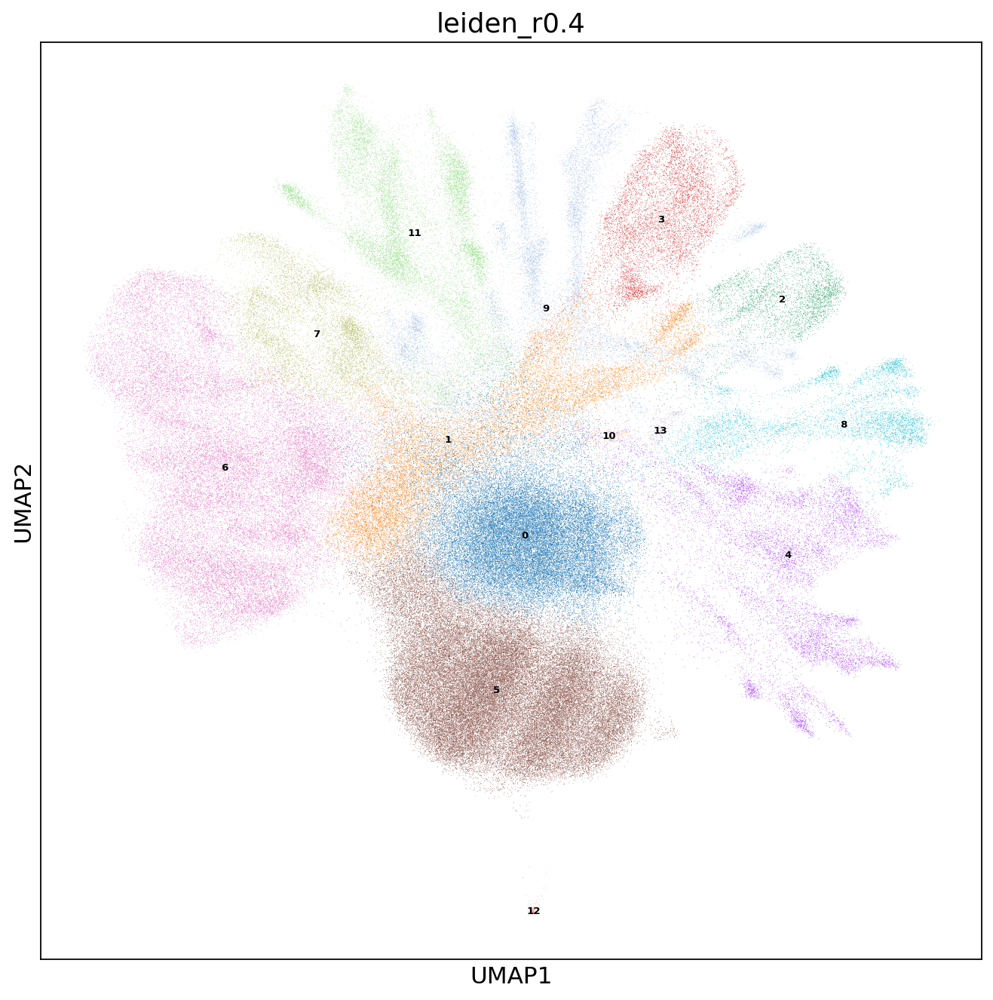

In [98]:
print(adata3.obs['leiden_r0.4'].unique())
sc.pl.umap(adata3, color='leiden_r0.4', legend_loc='on data')

In [99]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "leiden_r0.4"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata3.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata3[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata3.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


0                    → kept 500 / 39549 cells
1                    → kept 500 / 16876 cells
2                    → kept 500 / 4027 cells
3                    → kept 500 / 8085 cells
4                    → kept 500 / 11905 cells
5                    → kept 500 / 62539 cells
6                    → kept 500 / 35498 cells
7                    → kept 500 / 9168 cells
8                    → kept 500 / 6137 cells
9                    → kept 500 / 14568 cells
10                   → kept 206 / 206 cells
11                   → kept 500 / 15227 cells
12                   → kept 151 / 151 cells
13                   → kept 360 / 360 cells

Total cells before: 224296
Total cells after subsampling: 6217


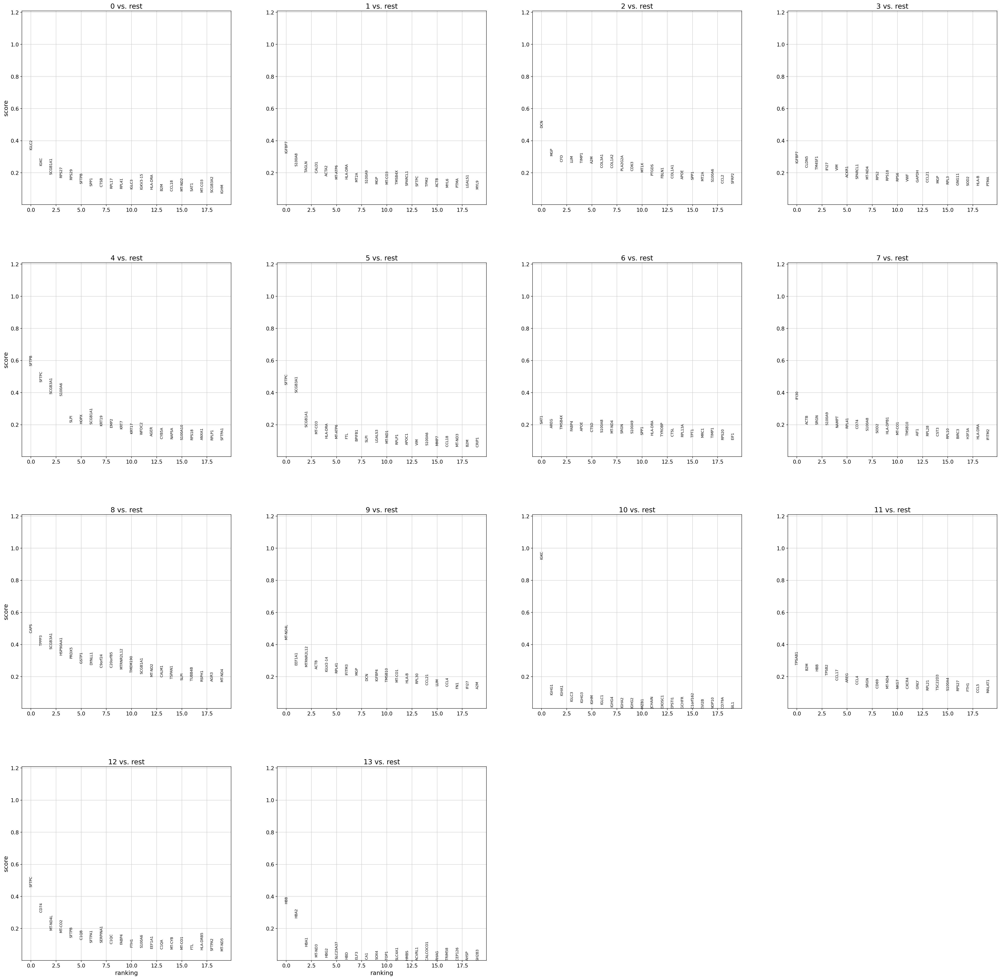

In [100]:
sc.tl.rank_genes_groups(adata_sub, groupby='leiden_r0.4', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

NORMALIZATION COMPARABILITY CHECK

[1/6] Loading dataset...
✓ Loaded: 224,296 cells × 18,433 genes
  Batches: ['GSE128169', 'GSE212109']

[3/6] Comparing value distributions across batches...
  (Using ALL cells - no subsampling)
  Processing GSE128169: 67,791 cells...
  Processing GSE212109: 156,505 cells...
  → Saved: check_1_value_distributions.png
     (Distributions should look similar if normalization worked)


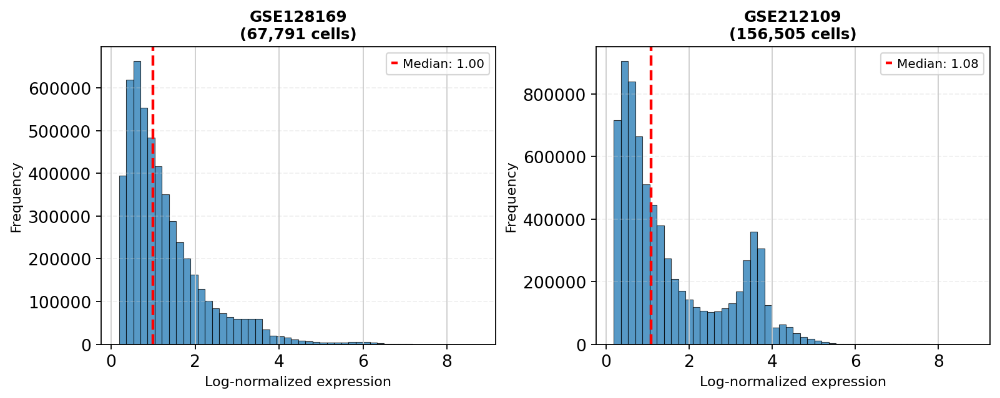

In [114]:
# ═══════════════════════════════════════════════════════════
# CONFIGURAZIONE
# ═══════════════════════════════════════════════════════════
adata_all = adata3

BATCH_KEY = "batch"
CELLTYPE_KEY = "cell_group"

print("="*70)
print("NORMALIZATION COMPARABILITY CHECK")
print("="*70)

# ═══════════════════════════════════════════════════════════
# 1. CARICA DATI
# ═══════════════════════════════════════════════════════════

print("\n[1/6] Loading dataset...")
# Assume adata_all already loaded
print(f"✓ Loaded: {adata_all.n_obs:,} cells × {adata_all.n_vars:,} genes")

batches = sorted(adata_all.obs[BATCH_KEY].unique())
print(f"  Batches: {batches}")



print("\n[3/6] Comparing value distributions across batches...")
print("  (Using ALL cells - no subsampling)")

# Calculate grid layout
n_batches = len(batches)
n_cols = min(3, n_batches)
n_rows = int(np.ceil(n_batches / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
if n_batches == 1:
    axes = np.array([axes])
axes = axes.flatten()

for idx, batch in enumerate(batches):
    mask = adata_all.obs[BATCH_KEY] == batch
    batch_data = adata_all[mask]
    
    print(f"  Processing {batch}: {batch_data.n_obs:,} cells...")
    
    # Extract ALL values (no subsampling)
    if hasattr(batch_data.X, 'toarray'):
        # Sparse matrix - sample genes to avoid memory issues
        # Take all cells but sample 1000 random genes
        n_genes_sample = min(1000, batch_data.n_vars)
        gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
        values = batch_data.X[:, gene_idx].toarray().flatten()
    else:
        # Dense matrix - can handle all
        if batch_data.n_obs * batch_data.n_vars > 10_000_000:
            # Too big - sample
            n_genes_sample = min(1000, batch_data.n_vars)
            gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
            values = batch_data.X[:, gene_idx].flatten()
        else:
            values = np.array(batch_data.X).flatten()
    
    # Remove zeros for clearer visualization
    values_nonzero = values[values > 0]
    
    # Plot histogram
    axes[idx].hist(values_nonzero, bins=50, alpha=0.75, edgecolor='black', linewidth=0.5)
    axes[idx].axvline(np.median(values_nonzero), color='red', linestyle='--', 
                      linewidth=2, label=f'Median: {np.median(values_nonzero):.2f}')
    
    axes[idx].set_title(f"{batch}\n({batch_data.n_obs:,} cells)", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Log-normalized expression", fontsize=10)
    axes[idx].set_ylabel("Frequency", fontsize=10)
    axes[idx].legend(fontsize=9)
    axes[idx].grid(axis='y', alpha=0.3, linestyle='--')

# Hide empty subplots
for idx in range(n_batches, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
print("  → Saved: check_1_value_distributions.png")
print("     (Distributions should look similar if normalization worked)")
#plt.close()

In [115]:
adata3.write("/home/ciperi/data/Atlas_SSC/LUNG/Unintegrated_Lung_V2_reann.h5ad")